<div style="display: flex; background-color: RGB(227, 128, 23);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU VENTES DE LA LIBRAIRIE LAPAGE - partie 1 </h1>
</div>

## L'objectif de ce Notebook
L'objectif de ce travail est d'analyser les ventes de la librairie LAPAGE en lignes afin de décider de la marche à suivre.

La section de nettoyage des données est divisée en plusieurs parties:

+ Chargement des bibliothèques et accès aux données
+ Exploration et nettoyage des jeux de données
+ Jointures des différents jeux de données

La section d'analyse des données est divisée en:

+ Analyse de différents indicateurs
+ Analyse du comportement des clients, notamment la corrélation entre plusieurs variables.


<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des jeux des données</h2>
</div>

<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.1 - Importation des librairies</h3>
</div>

In [379]:
# importation des  librairies
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
from scipy import stats
from scipy.stats import norm
from scipy.stats import shapiro
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import f_oneway
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd


<div style="border: 2px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">1.2 - Chargement des jeux de donnéess</h3>
</div>

In [380]:
# acceder au "working directory" pour avoir le nome de fichier
os.listdir()

['.ipynb_checkpoints',
 'Data',
 'Data_clean',
 'df_all_sans_BtoB.csv',
 'Figures',
 'Haraldsson_Matilda_1_notebook_022026.ipynb',
 'Haraldsson_Matilda_1_notebook_022026_copy.ipynb']

In [381]:
# Importation du fichier customers
df_cust = pd.read_csv("Data/customers.csv")
df_cust.shape

(8623, 3)

In [382]:
# Importation du fichier produits
df_prod = pd.read_csv("Data/products.csv")
df_prod.shape

(3287, 3)

In [383]:
# Importation du fichier customers
df_trans = pd.read_csv("Data/transactions.csv")
df_trans.shape

(679532, 4)

<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des jeux des données</h2>
</div>

## L'objective d'analyse exploratoire
L'analyse exploratoire poursuit un double objectif, premièrement, identifier et corriger les erreurs, notamment :
+ les valeurs manquantes (NaN)
+ les doublons
+ les valeurs aberrantes ou incohérentes

et deuxièmement, se familiariser avec chaque dataset et chaque variable.

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1 - Analyse exploratoire du fichier Custumer (df_cust)</h3>
</div>

In [384]:
#Afficher les 5 premières lignes de la table
df_cust.head()

,client_id,sex,birth
0,c_4410,f,1967
1,c_7839,f,1975
2,c_1699,f,1984
3,c_5961,f,1962
4,c_5320,m,1943


In [385]:
# information générale sur ce dataset
print("Nombre des observations:",df_cust.shape[0])
print("Nombre des variables:",df_cust.shape[1])
print()
print("Dèja, un peut constate que il n'y a pas de NaN et pas des lignes doublons dans ce dataset (voir ci-dessous):")
print()
print("Nombre des lignes dupliquées:",df_cust.duplicated().sum())
print()
df_cust.info()

Nombre des observations: 8623
Nombre des variables: 3

Dèja, un peut constate que il n'y a pas de NaN et pas des lignes doublons dans ce dataset (voir ci-dessous):

Nombre des lignes dupliquées: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8623 entries, 0 to 8622
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   client_id  8623 non-null   object
 1   sex        8623 non-null   object
 2   birth      8623 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 202.2+ KB


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1.1 - Analyse exploratoire de chaque variable du fichier df_cust</h3>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1.1.1 - Analyse de variable client_id</h3>
</div>

In [386]:
# explorer le variables "client_id"
# rechercher les doublons
print("Nombre des doublicat dans client_id:",
      df_cust["client_id"].duplicated().sum())
print()

print(f"{df_cust["client_id"].nunique()} clients sont inscrits en ligne")

Nombre des doublicat dans client_id: 0

8623 clients sont inscrits en ligne


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1.1.2 - Analyse de variable sex</h3>
</div>

Nombres: sex
f    4491
m    4132
Name: count, dtype: int64

Percentage: sex
f    52.081642
m    47.918358
Name: proportion, dtype: float64

LaPage compte presque autant de femmes que d'hommes parmi ses clients.



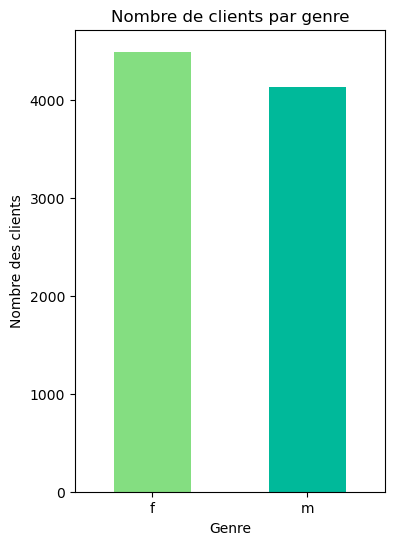

In [387]:
# explorer les modalités dans le variable "sex" et combien observations pour chaque modalité
print("Nombres:",df_cust["sex"].value_counts())
print()
print("Percentage:",df_cust["sex"].value_counts("n")*100)
print()
print("LaPage compte presque autant de femmes que d'hommes parmi ses clients.")
print()

# graphique barplot
plt.figure(figsize=(4,6))
df_cust["sex"].value_counts().plot(kind="bar", color=["#84de81","#00b99a"]) ##cf88c4,"#897456" , #7165a6
plt.title("Nombre de clients par genre")
plt.ylabel("Nombre des clients")
plt.xlabel("Genre")
plt.xticks(rotation=0)
plt.savefig("fig_no_clients_genre.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.1.1.3 - Analyse de variable birth</h3>
</div>

In [388]:
# explorer le variables "birth"
# valeures uniques pour l'années de naissance
df_cust["birth"].sort_values().unique()


array([1929, 1930, 1931, 1932, 1933, 1934, 1935, 1936, 1937, 1938, 1939,
       1940, 1941, 1942, 1943, 1944, 1945, 1946, 1947, 1948, 1949, 1950,
       1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961,
       1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972,
       1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983,
       1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994,
       1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004],
      dtype=int64)

In [389]:
# créer une variables l'age
df_cust["age"] = 2026 - df_cust["birth"]
df_cust.head()
df_cust["client_id"].nunique()

8623

La majorité des clients ont moins de 60 ans, et l'âge le plus courant est ~22-25 ans. 

Il est possible que les générations plus âgées utilisent moins souvent Internet pour acheter des livres, 
faute d'expérience avec les ordinateurs et Internet.



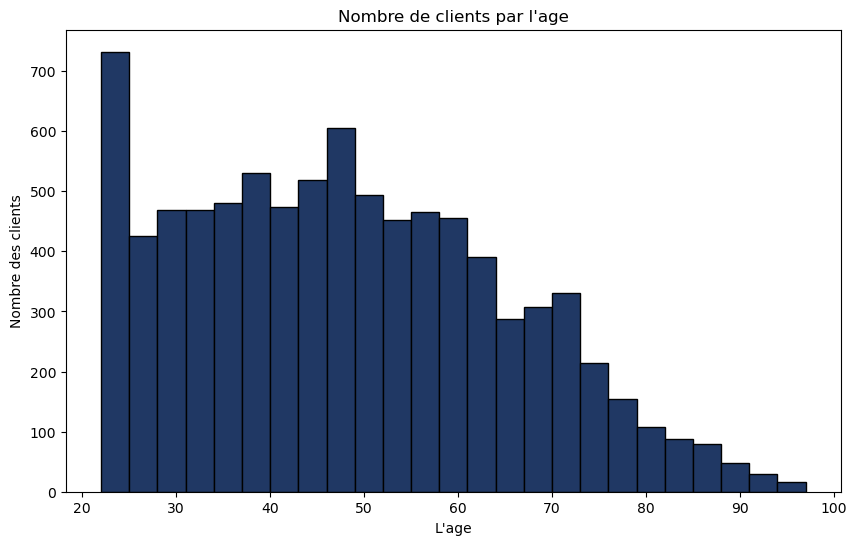

In [390]:
# graphique pour regarder le distribution de l'années de naissance

print("La majorité des clients ont moins de 60 ans, et l'âge le plus courant est ~22-25 ans. \n\nIl est possible que les générations plus âgées utilisent moins souvent Internet pour acheter des livres, \nfaute d'expérience avec les ordinateurs et Internet.")
print()
# graphique histogram
plt.figure(figsize=(10,6))
plt.hist(df_cust["age"], bins=25, edgecolor="black", color="#203864")  #"#203864","#897456","#7165a6"
plt.title("Nombre de clients par l'age")
plt.ylabel("Nombre des clients")
plt.xlabel("L'age")
plt.savefig("fig_hist_age_clients.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2 - Analyse exploratoire du jeux de donnée Produits</h3>
</div>

In [391]:
#Afficher les 5 premières lignes de la table
df_prod.head()

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0


In [392]:
# information générale sur ce dataset
print("Nombre des observations:",df_prod.shape[0])
print("Nombre des variables:",df_prod.shape[1])
print()
print("Dèja, un peut constate que il n'y a pas de NaN et pas des lignes doublons dans ce dataset (voir ci-dessous):")
print()
print("Nombre des lignes dupliquées:",df_prod.duplicated().sum())
print()
df_prod.info()

Nombre des observations: 3287
Nombre des variables: 3

Dèja, un peut constate que il n'y a pas de NaN et pas des lignes doublons dans ce dataset (voir ci-dessous):

Nombre des lignes dupliquées: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3287 entries, 0 to 3286
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id_prod  3287 non-null   object 
 1   price    3287 non-null   float64
 2   categ    3287 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 77.2+ KB


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2.1 - Analyse exploratoire de chaque variable du fichier df_prod</h3>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2.1.1 - Analyse de variable id_prod</h3>
</div>

In [398]:
# rechercher les doublons
print("Nombre des doublicat dans id_prod:",
      df_prod["id_prod"].duplicated().sum())


Nombre des doublicat dans id_prod: 0


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2.1.2 - Analyse de variable price</h3>
</div>

In [399]:
# explorer les statistiques le variable prix
print("Il y a des prix négatifs, c'est une erreur (voir ci-dessous)")
print()
print(df_prod["price"].describe())
print()
mask = df_prod["price"] < 0
df_prod[mask]

Il y a des prix négatifs, c'est une erreur (voir ci-dessous)

count    3287.000000
mean       21.856641
std        29.847908
min        -1.000000
25%         6.990000
50%        13.060000
75%        22.990000
max       300.000000
Name: price, dtype: float64



,id_prod,price,categ
731,T_0,-1.0,0


In [400]:
# supprimer cette obervation avec une erreurs de prix
print(f"Comme nous n'avons qu'une seule valeur aberrante sur {df_prod.shape[0]} observations ({round(((1/df_prod.shape[0])*100),2)}%), nous l'excluons.")
df_prod = df_prod[~mask]
print()
print("Nombres d'observations dans le dataset apres l'exclustion d'erreur:",df_prod.shape[0])


Comme nous n'avons qu'une seule valeur aberrante sur 3287 observations (0.03%), nous l'excluons.

Nombres d'observations dans le dataset apres l'exclustion d'erreur: 3286


La distribution des prix suit une loi de Poisson. 
La plupart des livres sont peu chers, entre < 20 euros. Les livres coûtant plus de 50 euros sont rares. 

Le prix des livres dépend de leur catégorie.



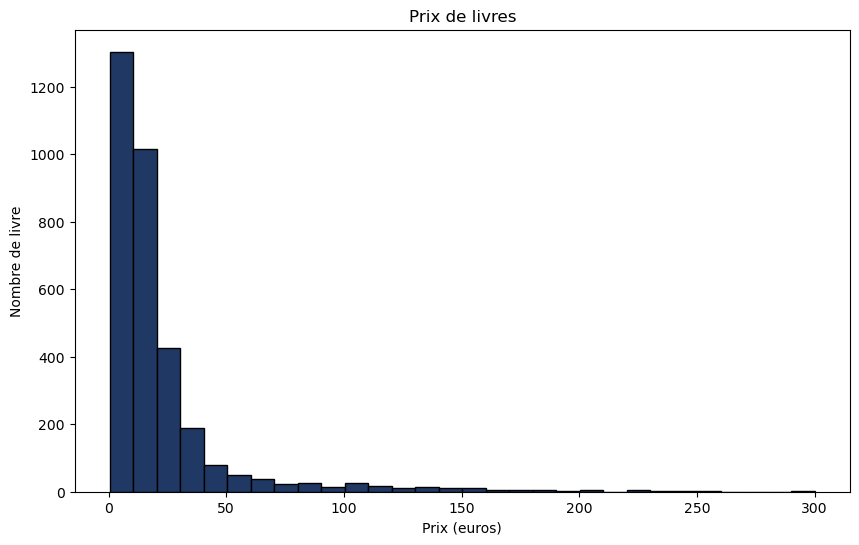

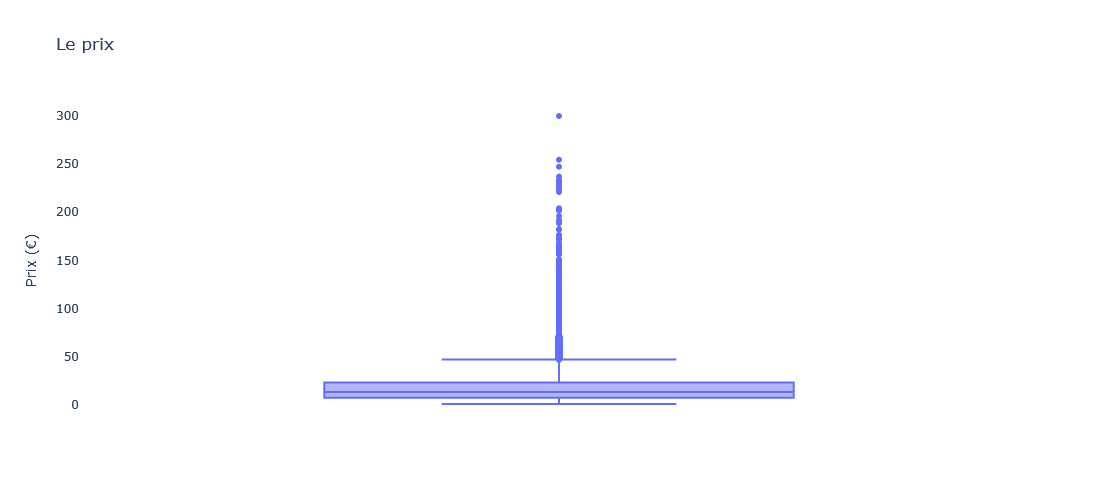

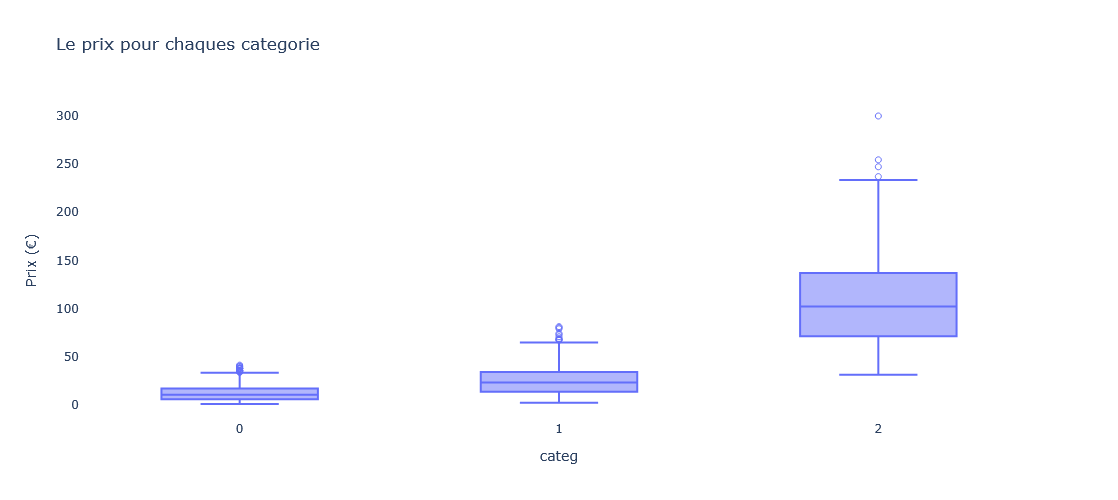

In [401]:
# graphique pour regarder le distribution du prix
print("La distribution des prix suit une loi de Poisson. \nLa plupart des livres sont peu chers, entre < 20 euros. Les livres coûtant plus de 50 euros sont rares. \n\nLe prix des livres dépend de leur catégorie.")
print()
# graphique histogram
plt.figure(figsize=(10,6))
plt.hist(df_prod["price"], bins=30, edgecolor="black",color="#203864")
plt.title("Prix de livres")
plt.xlabel("Prix (euros)")
plt.ylabel("Nombre de livre")
plt.show()
print()

# boxplot pour le prix
fig = px.box(
    df_prod,
    y="price",
    points="suspectedoutliers",
    title="Le prix",
    width=400, height=500
)
fig.update_layout(
    yaxis_title="Prix (€)",
    plot_bgcolor="white"
)
fig.show()
print()

# boxplot pour le prix pour chaques categorie
fig = px.box(
    df_prod,
    y="price",
    x="categ",
    points="suspectedoutliers",
    title="Le prix pour chaques categorie",
    width=400, height=500
)
fig.update_layout(
    yaxis_title="Prix (€)",
    plot_bgcolor="white"
)
fig.show()


C:\Users\matil\AppData\Local\Temp\ipykernel_26128\798147429.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




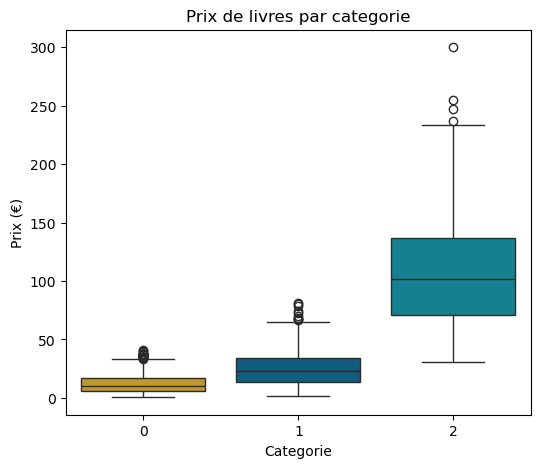

In [402]:
# boxplot prix des livres
plt.figure(figsize=(6,5))
sns.boxplot(y="price", x="categ",data=df_prod, palette=["#d5a419","#006390","#008fa4"]) # ["#006390","#008fa4","#d5a419"]
plt.title("Prix de livres par categorie")
plt.ylabel("Prix (€)")
plt.xlabel("Categorie")
plt.xticks(rotation=0)
plt.savefig("fig_prix_par_categ.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.2.1.3 - Analyse de variable categ</h3>
</div>

Nombres: categ
0    2308
1     739
2     239
Name: count, dtype: int64

Percentage: categ
0    70.237371
1    22.489349
2     7.273281
Name: proportion, dtype: float64

Les produits de LaPage sont clairement dominés par la catégorie 0, suivie de la catégorie 1 et enfin de la catégorie 2.



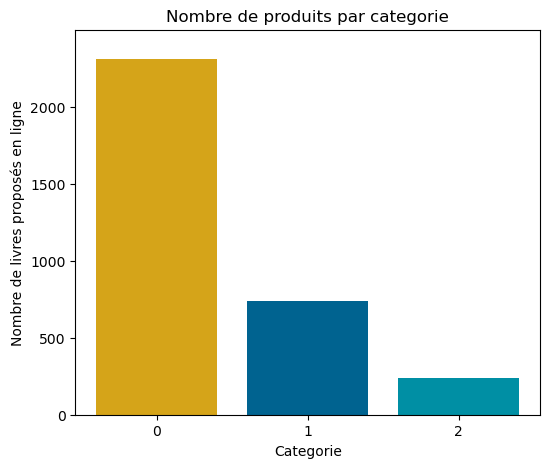

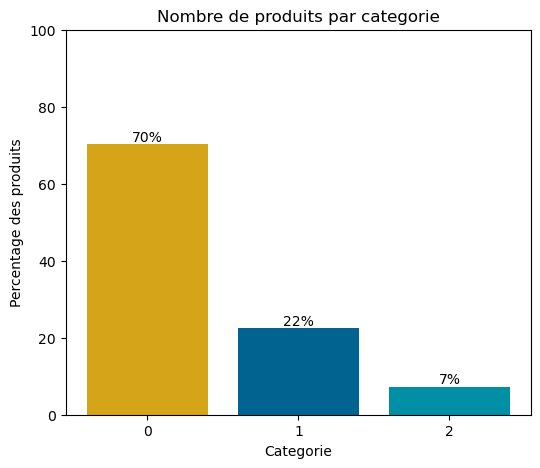

In [403]:
data_categ = df_prod["categ"].value_counts()
data_categ_names = (df_prod["categ"].value_counts("n")).index 
data_categ_prop = (df_prod["categ"].value_counts("n") * 100).values
# explorer les modalités dans le variable "categ" et combien observations pour chaque modalité
print("Nombres:",data_categ)
print()
print("Percentage:",df_prod["categ"].value_counts("n") * 100)
print()
print("Les produits de LaPage sont clairement dominés par la catégorie 0, suivie de la catégorie 1 et enfin de la catégorie 2.")
print()

# graphique barplot - nombres de livres
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(data_categ_names, data_categ, color=["#d5a419","#006390","#008fa4"]) 
ax.set(ylabel="Nombre de livres proposés en ligne", xlabel="Categorie", title="Nombre de produits par categorie", ylim=(0,2499), xticks=(0,1,2))
#ax.bar_label(bar_plot, fmt="{:,.0f}%")
plt.savefig("fig_no_livres_par_categ.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

print()

# graphique barplot - precentage de livres
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(data_categ_names, data_categ_prop, color=["#d5a419","#006390","#008fa4"])  # "#203864","#897456","#7165a6"
ax.set(ylabel="Percentage des produits", xlabel="Categorie", title="Nombre de produits par categorie", ylim=(0, 100), xticks=(0,1,2))
ax.bar_label(bar_plot, fmt="{:,.0f}%")
plt.savefig("fig_percentage_livres_par_categ.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()



<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3 - Analyse exploratoire du jeux de donnée Transaction</h3>
</div>

In [404]:
#Afficher les 5 premières lignes de la table
df_trans.head()

,id_prod,date,session_id,client_id
0,0_1518,2022-05-20 13:21:29.043970,s_211425,c_103
1,1_251,2022-02-02 07:55:19.149409,s_158752,c_8534
2,0_1277,2022-06-18 15:44:33.155329,s_225667,c_6714
3,2_209,2021-06-24 04:19:29.835891,s_52962,c_6941
4,0_1509,2023-01-11 08:22:08.194479,s_325227,c_4232


In [405]:
# information générale sur ce dataset
print("Nombre des observations:",df_trans.shape[0])
print("Nombre des variables:",df_trans.shape[1])
print()
print("Dèja, un peut constate que il n'y a pas de NaN, mais on a des doublons (voir ci-dessous):")
print()
print("Nombre des lignes dupliquées:",df_trans.duplicated().sum())
print()
df_trans.info()



Nombre des observations: 679532
Nombre des variables: 4

Dèja, un peut constate que il n'y a pas de NaN, mais on a des doublons (voir ci-dessous):

Nombre des lignes dupliquées: 126

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 679532 entries, 0 to 679531
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_prod     679532 non-null  object
 1   date        679532 non-null  object
 2   session_id  679532 non-null  object
 3   client_id   679532 non-null  object
dtypes: object(4)
memory usage: 20.7+ MB


In [406]:
# Examinez de plus près les doublons et traitez-les
print("Ces doublons semblent provenir d'une session de test (date avec 'test_' dans le date, et id_prod avec T_0). \n\nEn plus, comme ils sont enregistrés simultanément, à quelques décimales de seconde près, il s'agit probablement \nd'erreurs qui ne devraient pas figurer dans la base de données. Examinons de plus près les séances de test !.")
print()


mask = df_trans.duplicated(keep=False)
print("Tous les doublons ont-ils id_prod = T_0 ?   ", ((df_trans.loc[mask,"id_prod"] == "T_0").sum()) == (df_trans[mask].shape[0]))
print()
df_trans[mask].sort_values(by="date")


Ces doublons semblent provenir d'une session de test (date avec 'test_' dans le date, et id_prod avec T_0). 

En plus, comme ils sont enregistrés simultanément, à quelques décimales de seconde près, il s'agit probablement 
d'erreurs qui ne devraient pas figurer dans la base de données. Examinons de plus près les séances de test !.

Tous les doublons ont-ils id_prod = T_0 ?    True



,id_prod,date,session_id,client_id
96687,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
91133,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
548383,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
453857,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
606326,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
...,...,...,...,...
312697,T_0,test_2021-03-01 02:30:02.237447,s_0,ct_1
621687,T_0,test_2021-03-01 02:30:02.237447,s_0,ct_1
320833,T_0,test_2021-03-01 02:30:02.237447,s_0,ct_1
19312,T_0,test_2021-03-01 02:30:02.237449,s_0,ct_0


In [408]:
# vérifier que tous les id_prod sont T_0
mask_all = df_trans["id_prod"] == "T_0"
print("Nombre des lignes avec T_0 dans id_prod:",mask_all.sum())
print()

print("Tous les T_0 sont enregistrés simultanément, à une seconde près. Nous excluons toutes les sessions de test")
print()

# montres tout les données avec id_prod = T_0
df_trans[mask_all].sort_values(by="date")


Nombre des lignes avec T_0 dans id_prod: 200

Tous les T_0 sont enregistrés simultanément, à une seconde près. Nous excluons toutes les sessions de test



,id_prod,date,session_id,client_id
96687,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
453857,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
91133,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
607892,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_0
548383,T_0,test_2021-03-01 02:30:02.237412,s_0,ct_1
...,...,...,...,...
392443,T_0,test_2021-03-01 02:30:02.237448,s_0,ct_0
19312,T_0,test_2021-03-01 02:30:02.237449,s_0,ct_0
670680,T_0,test_2021-03-01 02:30:02.237449,s_0,ct_1
573155,T_0,test_2021-03-01 02:30:02.237449,s_0,ct_0


In [411]:
# supprimer les lignes correspondant au sessions de test, et vérifiez qu'il n'y a pas de lignes dupliquées
df_trans = df_trans[~mask_all]
df_trans.duplicated(keep=False).sum()

C:\Users\matil\AppData\Local\Temp\ipykernel_26128\1963775957.py:2: UserWarning:

Boolean Series key will be reindexed to match DataFrame index.



0

In [412]:
# dimentions de dataset apres le suppmimation de données "test"
df_trans.shape

(679332, 4)

In [413]:
# nettoyer et transformer la variable date en objet datetime
#date_clean = df_trans["date"].str.replace("test_","",regex=False)
date_clean = pd.to_datetime(df_trans["date"],format="mixed",yearfirst=True)
df_trans.loc[:,"date"] = date_clean
df_trans.info()

<class 'pandas.core.frame.DataFrame'>
Index: 679332 entries, 0 to 679531
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_prod     679332 non-null  object
 1   date        679332 non-null  object
 2   session_id  679332 non-null  object
 3   client_id   679332 non-null  object
dtypes: object(4)
memory usage: 25.9+ MB


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3.1 - Analyse exploratoire de chaque variable du fichier transactions (df_trans)</h3>
</div>


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3.1.1 - Analyse de variable product_id</h3>
</div>

In [414]:
# rechercher les doublons
print("Nombre de doublons dans id_prod:",df_trans["id_prod"].duplicated().sum())
print()
print("Les doublons sont logique pour cette variable dans ce dataset: la même produit peut être acheté par différents clients")

Nombre de doublons dans id_prod: 676066

Les doublons sont logique pour cette variable dans ce dataset: la même produit peut être acheté par différents clients


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3.1.2 - Analyse de variable date</h3>
</div>

In [415]:
# rechercher les doublons
print("Nombre de doublons dans date:",df_trans["date"].duplicated().sum())


Nombre de doublons dans date: 0


Le nombre de transactions est resté relativement constant au cours des deux dernières années.



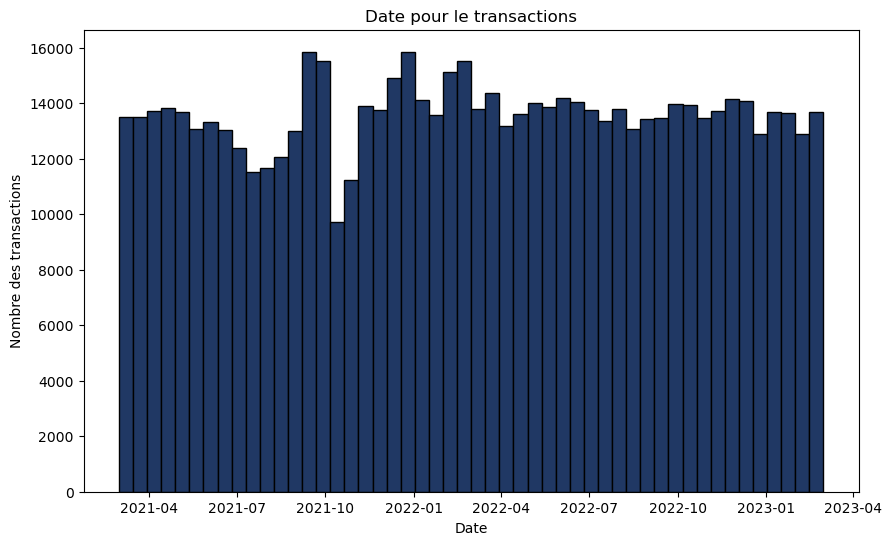

In [416]:
# graphique pour regarder le distribution du prix
print("Le nombre de transactions est resté relativement constant au cours des deux dernières années.")
print()
# graphique histogram
plt.figure(figsize=(10,6))
plt.hist(df_trans["date"], bins=50, edgecolor="black", color="#203864")
plt.title("Date pour le transactions")
plt.xlabel("Date")
plt.ylabel("Nombre des transactions")
plt.show()
print()


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3.1.3 - Analyse de variable session_id</h3>
</div>

In [417]:
# rechercher les doublons
print("Nombre de doublons dans session_id:",df_trans["session_id"].duplicated().sum())
print()

print("Les doublons sont logique pour cette variable dans ce dataset: Il est possible d'acheter plusieurs livres lors d'une même transaction.")

Nombre de doublons dans session_id: 337017

Les doublons sont logique pour cette variable dans ce dataset: Il est possible d'acheter plusieurs livres lors d'une même transaction.


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">2.3.1.4 - Analyse de variable client_id</h3>
</div>

In [418]:
# Examinez le nombre de doublons dans chaque variable
print("Nombre de doublons dans client_id:",df_trans["client_id"].duplicated().sum())
print()
print("Les doublons sont logique pour cette variable dans ce dataset: un même client peut acheter \nplusieurs livres (à la même occasion ou à des occasions différentes).")

Nombre de doublons dans client_id: 670732

Les doublons sont logique pour cette variable dans ce dataset: un même client peut acheter 
plusieurs livres (à la même occasion ou à des occasions différentes).


<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Junction du jeux des données</h2>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.1 - Jonction du fichiers df_trans et df_cust</h3>
</div>

In [419]:
# fusionner les datasets df_trans avec df_cust
df_merge_in = pd.merge(df_trans, df_cust, on="client_id", how="inner")
#df_merge_out = pd.merge(df_trans, df_cust, on="client_id", how="outer")

print("Comparez la dimention des datasets avant et après la fusion:")
print("df_cust:",df_cust.shape)
print("df_trans:",df_trans.shape)
print("df_merge:",df_merge_in.shape)

Comparez la dimention des datasets avant et après la fusion:
df_cust: (8623, 4)
df_trans: (679332, 4)
df_merge: (679332, 7)


In [420]:
# verifier si il y a des lignes sans correspondance => Transaction manquante
sans_corr = set(df_cust["client_id"]) - set(df_trans["client_id"]) 
                                                     # note: set plus vite pour le grande dataset
df_client_non_actif = df_cust[df_cust["client_id"].isin(sans_corr)]
print(f"{len(sans_corr)} lignes qui ne correspondent pas dans df_trans")
print()
print("Ces observations correspondent à des clients qui n'ont acheté aucun livre \ndepuis que la librairie est passée au format online (ces 2 dernières années).")
print()
df_client_non_actif.head()

23 lignes qui ne correspondent pas dans df_trans

Ces observations correspondent à des clients qui n'ont acheté aucun livre 
depuis que la librairie est passée au format online (ces 2 dernières années).



,client_id,sex,birth,age
801,c_8253,f,2001,25
2483,c_3789,f,1997,29
2734,c_4406,f,1998,28
2735,ct_0,f,2001,25
2769,c_2706,f,1967,59


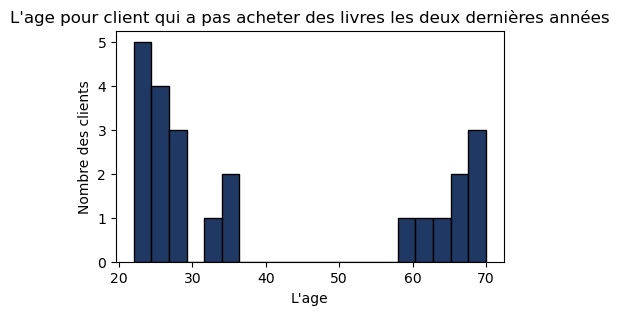

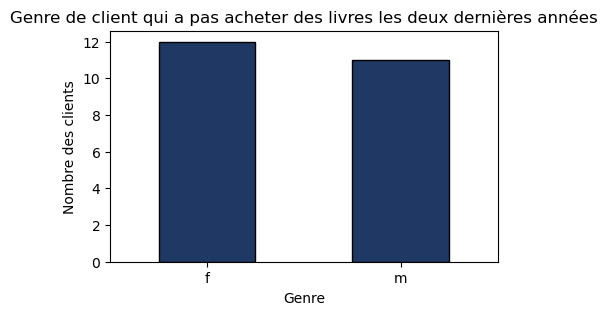

In [423]:
# graphique histogram
plt.figure(figsize=(5,3))
plt.hist(df_client_non_actif["age"], bins=20, edgecolor="black",color="#203864")
plt.title("L'age pour client qui a pas acheter des livres les deux dernières années")
plt.xlabel("L'age")
plt.ylabel("Nombre des clients")
plt.show()
print()

# graphique barplot par gendre
plt.figure(figsize=(5,3))
df_client_non_actif["sex"].value_counts().plot(kind="bar",edgecolor="black",color="#203864")
plt.title("Genre de client qui a pas acheter des livres les deux dernières années")
plt.ylabel("Nombre des clients")
plt.xlabel("Genre")
plt.xticks(rotation=0)
plt.show()


In [424]:
# verifier si il y a des lignes sans correspondance => Clients manquante
sans_corr = set(df_trans["client_id"]) - set(df_cust["client_id"])
print(f"{len(sans_corr)} lignes qui ne correspondent pas dans df_cust")


0 lignes qui ne correspondent pas dans df_cust


<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 3.1 - Jonction du fichiers df_merge et df_prod</h3>
</div>

In [425]:
# fusionner les datasets df_merge avec df_prod
df_all_in = pd.merge(df_merge_in, df_prod, on="id_prod", how="inner")
df_all_out = pd.merge(df_merge_in, df_prod, on="id_prod", how="outer")

df_all_in = df_all_in.sort_values(by="date")
df_all_in.head()

,id_prod,date,session_id,client_id,sex,birth,age,price,categ
480353,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,f,1967,59,11.99,0
428221,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,m,1960,66,19.37,0
462423,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,m,1988,38,4.50,0
488002,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912,f,1989,37,6.55,0
438813,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033,f,1956,70,16.49,0


In [426]:
# verifier si il y a des lignes sans correspondance => Transaction manquante
sans_corr = set(df_prod["id_prod"]) - set(df_merge_in["id_prod"])
print(f"{len(sans_corr)} lignes qui ne correspondent pas dans df_merge (=> df_trans)")
print()
print("Ces observations correspondent à des produits/livres qui n'ont pas été vendus depuis deux ans.")
print()

produits_non_vendue = df_all_out[df_all_out["id_prod"].isin(sans_corr)]
produits_non_vendue.head()

21 lignes qui ne correspondent pas dans df_merge (=> df_trans)

Ces observations correspondent à des produits/livres qui n'ont pas été vendus depuis deux ans.



,id_prod,date,session_id,client_id,sex,birth,age,price,categ
6073,0_1014,NaN,NaN,NaN,NaN,NaN,NaN,1.15,0.0
6511,0_1016,NaN,NaN,NaN,NaN,NaN,NaN,35.06,0.0
8723,0_1025,NaN,NaN,NaN,NaN,NaN,NaN,24.99,0.0
21687,0_1062,NaN,NaN,NaN,NaN,NaN,NaN,20.08,0.0
40971,0_1119,NaN,NaN,NaN,NaN,NaN,NaN,2.99,0.0


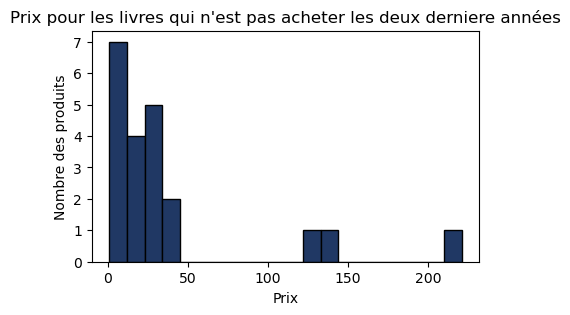

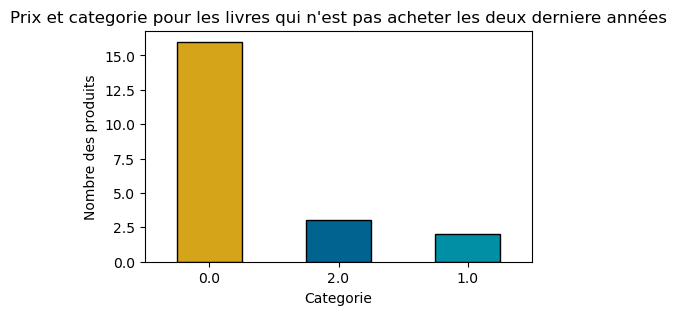

In [428]:
# graphique histogram
plt.figure(figsize=(5,3))
plt.hist(produits_non_vendue["price"], bins=20, edgecolor="black",color="#203864")
plt.title("Prix pour les livres qui n'est pas acheter les deux derniere années")
plt.xlabel("Prix")
plt.ylabel("Nombre des produits")
plt.show()
print()

# graphique barplot par gendre
plt.figure(figsize=(5,3))
produits_non_vendue["categ"].value_counts().plot(kind="bar",edgecolor="black",color=["#d5a419","#006390","#008fa4"])
plt.title("Prix et categorie pour les livres qui n'est pas acheter les deux derniere années")
plt.ylabel("Nombre des produits")
plt.xlabel("Categorie")
plt.xticks(rotation=0)
plt.show()


In [429]:
# verifier si il y a des lignes sans correspondance => Produits manquante

sans_corr = set(df_merge_in["id_prod"]) - set(df_prod["id_prod"])
print(f"{len(sans_corr)} lignes qui ne correspondent pas dans df_prod")
produits_manquants = df_all_out[df_all_out["id_prod"].isin(sans_corr)]
print()
print(f"Cette observation concerne un produit/livre vendu, mais dont nous ne disposons pas du prix. \n\nÀ NOTER : ce livre a été vendu {produits_manquants.shape[0]} fois (cela ne représente que {round((produits_manquants.shape[0]/df_all_out.shape[0] * 100),2)} % de toutes les transactions).")
print()
produits_manquants



1 lignes qui ne correspondent pas dans df_prod

Cette observation concerne un produit/livre vendu, mais dont nous ne disposons pas du prix. 

À NOTER : ce livre a été vendu 221 fois (cela ne représente que 0.03 % de toutes les transactions).



,id_prod,date,session_id,client_id,sex,birth,age,price,categ
380106,0_2245,2022-09-23 07:22:38.636773,s_272266,c_4746,m,1940.0,86.0,NaN,NaN
380107,0_2245,2022-07-23 09:24:14.133889,s_242482,c_6713,f,1963.0,63.0,NaN,NaN
380108,0_2245,2022-12-03 03:26:35.696673,s_306338,c_5108,m,1978.0,48.0,NaN,NaN
380109,0_2245,2021-08-16 11:33:25.481411,s_76493,c_1391,m,1991.0,35.0,NaN,NaN
380110,0_2245,2022-07-16 05:53:01.627491,s_239078,c_7954,m,1973.0,53.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...
380322,0_2245,2021-08-25 09:06:03.504061,s_80395,c_131,m,1981.0,45.0,NaN,NaN
380323,0_2245,2022-03-06 19:59:19.462288,s_175311,c_4167,f,1979.0,47.0,NaN,NaN
380324,0_2245,2022-05-16 11:35:20.319501,s_209381,c_4453,m,1981.0,45.0,NaN,NaN
380325,0_2245,2022-02-11 09:05:43.952857,s_163405,c_1098,m,1986.0,40.0,NaN,NaN


### Créez deux ensembles de données:
+ Le premier contient uniquement les données transactionnelles fusionnées pour lesquelles des informations produit et client sont associées (il servira à l'analyse des produits).
+ Le deuxiemme contient toutes les données transactionnelles fusionnées, y compris les lignes pour lesquelles les informations produit sont manquantes (il servira à l'analyse des clients).


In [430]:
# création des deux ensembles de données

# premiere dataset - (tout les transactions avec correspondance)
df_all = df_all_in
df_all = df_all.sort_values(by="date")
print("Dimension pour le dataset:", df_all.shape)


# deuxiemme dataset - plus long, avec information manquantes pour une produits ventues plusiers fois
mask = df_all_out["date"].isna()
df_all_long = df_all_out[~mask]
df_all_long = df_all_long.sort_values(by="date")
print("Dimension pour le dataset plus long:", df_all_long.shape)


Dimension pour le dataset: (679111, 9)
Dimension pour le dataset plus long: (679332, 9)


In [431]:
print(f"{df_all["client_id"].nunique()} clients ont été actifs au cours des deux dernières années.")

8600 clients ont été actifs au cours des deux dernières années.


<div style="background-color: RGB(227, 128, 23);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse des indicateurs de ventes</h2>
</div>

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 4.1 - Chiffres d affaires</h3>
</div>

In [432]:
################################################################################################################
### Chiffres d'affaires avec moyenne mobile
################################################################################################################
print(f"Le chiffre d'affaires total entre 2021-2023 était: {(df_all["price"].sum()):,.0f} €".replace(",", " "))
print()

# CA par années (mars jusqua fin fevrier)
mask = df_all["date"] < pd.Timestamp("2022-03-01")
df_all_2021 = df_all[mask]
mask = df_all["date"] >= pd.Timestamp("2022-03-01")
df_all_2022 = df_all[mask]
print(f"Le chiffre d'affaires total en 2021: {(df_all_2021["price"].sum()):,.0f} €".replace(",", " "))
print(f"Le chiffre d'affaires total en 2022: {(df_all_2022["price"].sum()):,.0f} €".replace(",", " "))


Le chiffre d'affaires total entre 2021-2023 était: 11 853 729 €

Le chiffre d'affaires total en 2021: 5 831 737 €
Le chiffre d'affaires total en 2022: 6 021 992 €


In [433]:
# Créez une variable contenant la date sans l'heure
df_all["date_y_m_d"] = pd.to_datetime(df_all["date"]).dt.date
df_all.head()

print(f"Il y a {len(df_all["date_y_m_d"].unique())} date uniques dans le dataset")

Il y a 730 date uniques dans le dataset


In [434]:
# calquler les chiffre d'affaires pour chaque jour avec une transactions
df_CA_date = df_all[["price","age","categ","date_y_m_d"]].groupby(by="date_y_m_d").agg({"price": "sum","age": "mean", "categ": "mean"})
df_CA_date = df_CA_date.reset_index()

print(f"Le CA moyen par date de vente est: {(df_CA_date["price"].mean()):,.0f} €".replace(","," "))
print()
df_CA_date.head()


Le CA moyen par date de vente est: 16 238 €



,date_y_m_d,price,age,categ
0,2021-03-01,16565.22,48.504158,0.443867
1,2021-03-02,15486.45,48.358892,0.385517
2,2021-03-03,15198.69,48.274424,0.395170
3,2021-03-04,15196.07,49.119601,0.424142
4,2021-03-05,17471.37,47.704136,0.459173


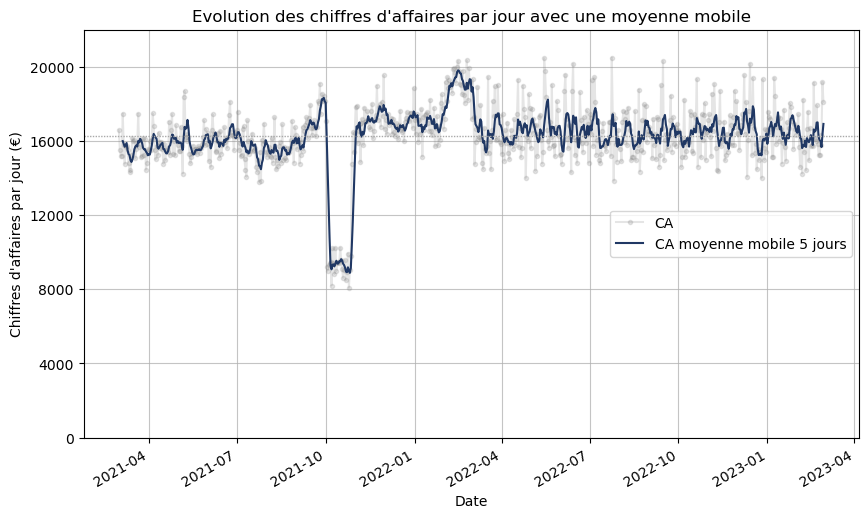

In [435]:
# création de graphique en ligne
mobile = 5
plt.figure(figsize=(10,6))

plt.plot(
    df_CA_date["date_y_m_d"],df_CA_date["price"],
    marker=".", 
    linestyle="-",
    color="gray",
    alpha=0.2,
    label="CA"
)

plt.plot(
    df_CA_date["date_y_m_d"],df_CA_date["price"].rolling(mobile).mean(), 
    #marker="o", 
    linestyle="-",
    color="#203864",
    alpha=1,
    label =f"CA moyenne mobile {mobile} jours"
)
plt.title("Evolution des chiffres d'affaires par jour avec une moyenne mobile")
plt.xlabel("Date")
plt.ylabel("Chiffres d'affaires par jour (€)")
plt.ylim(0,22000)
plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=0.75)
plt.grid(True, alpha=0.75)

# formater l'axe des X pour afficher les dates correctement !!! 
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
#plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
plt.axhline(y=df_CA_date["price"].mean(), dashes=(1, 1), linewidth=1, color="darkgray") # Dotted line using dashes

plt.legend(loc = 7)
plt.savefig("fig_CA_avec_time_moy_mobile_1.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

In [436]:
# calquler les chiffre d'affaires pour chaque jouravec une transactions et caregorie 
df_CA_date_cat = df_all[["price","age","categ","date_y_m_d"]].groupby(by=["date_y_m_d","categ"]).agg({"price": "sum","age": "mean"})
df_CA_date_cat = df_CA_date_cat.reset_index()

print(f"Le revenu moyen par date de vente est: {(df_CA_date_cat["price"].mean()):,.0f} €".replace(","," "))
print()
df_CA_date_cat.head()


Le revenu moyen par date de vente est: 5 478 €



,date_y_m_d,categ,price,age
0,2021-03-01,0,6262.65,48.068847
1,2021-03-01,1,6811.53,51.919403
2,2021-03-01,2,3491.04,29.130435
3,2021-03-02,0,6718.27,47.811290
4,2021-03-02,1,5627.15,52.626812


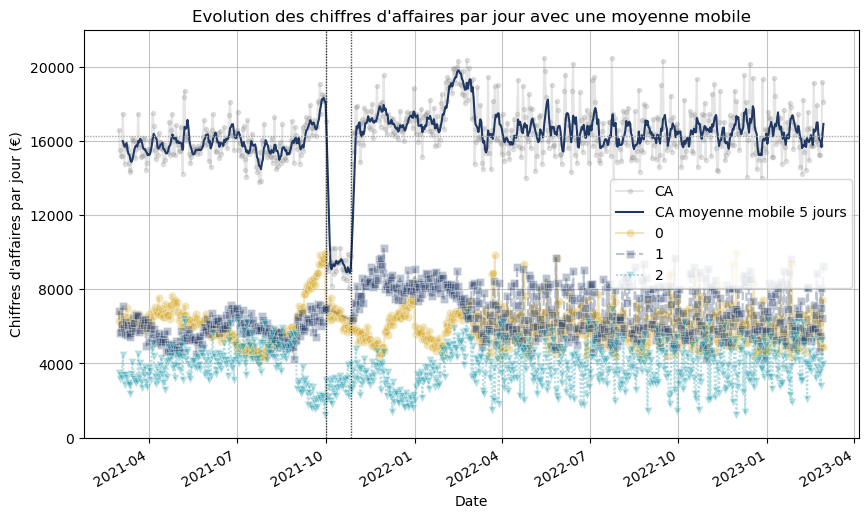

In [437]:
# création de graphique en ligne
plt.figure(figsize=(10,6))

plt.plot(
    df_CA_date["date_y_m_d"],df_CA_date["price"],
    marker=".", 
    linestyle="-",
    color="gray",
    alpha=0.2,
    label="CA"
)

plt.plot(
    df_CA_date["date_y_m_d"],df_CA_date["price"].rolling(mobile).mean(), 
    #marker="o", 
    linestyle="-",
    color="#203864",
    alpha=1,
    label =f"CA moyenne mobile {mobile} jours"
)

# definir les categories et leur markers 
categories = df_CA_date_cat["categ"].unique()
marker_dict = dict(zip(categories, ["o", "s", "v"]))

sns.lineplot(
    x=df_CA_date_cat["date_y_m_d"], y=df_CA_date_cat["price"], 
    hue=df_CA_date_cat["categ"], 
    style=df_CA_date_cat["categ"],
    markers=marker_dict,  # Dictionary mapping categories to specific markers
    palette=["#d5a419","#203864","#008fa4"],
    marker="o",
    alpha=0.3
)
plt.title("Evolution des chiffres d'affaires par jour avec une moyenne mobile")
plt.xlabel("Date")
plt.ylabel("Chiffres d'affaires par jour (€)")
plt.ylim(0,22000)
plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=0.75)
plt.grid(True, alpha=0.75)

# formater l'axe des X pour afficher les dates correctement !!! 
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
#plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
plt.legend(loc = 7)
           #labels=["CA","CA mobile mean","categ 0","categ 1","categ 2"]
plt.axhline(y=df_CA_date["price"].mean(), dashes=(1, 1), linewidth=1, color="darkgray") # Dotted line using dashes
plt.axvline(x=pd.Timestamp("2021-10-01").date(), dashes=(1, 1), linewidth=1, color="black", alpha=0.7) # Dotted line using dashes
plt.axvline(x=pd.Timestamp("2021-10-27").date(), dashes=(1, 1), linewidth=1, color="black", alpha=0.7) # Dotted line using dashes
plt.savefig("fig_CA_avec_time_moy_mobile_2.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

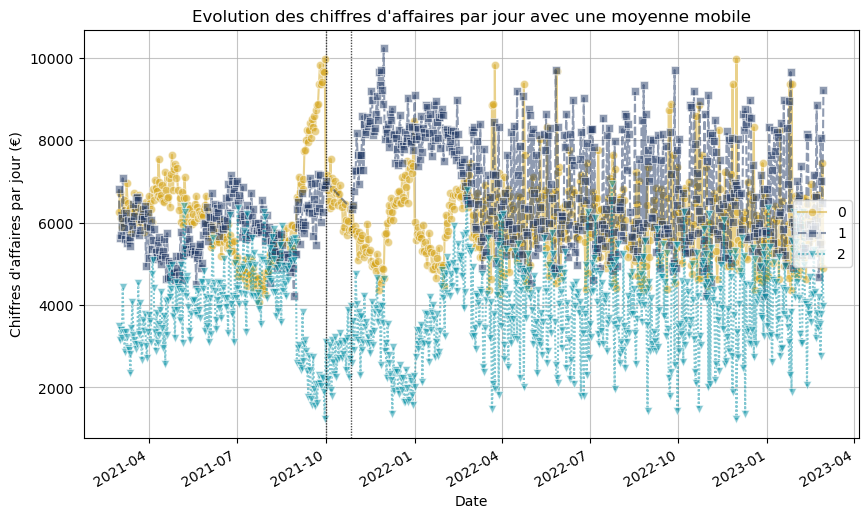

In [438]:
# création de graphique en ligne
mobile = 10
plt.figure(figsize=(10,6))

# definir les categories et leur markers 
categories = df_CA_date_cat["categ"].unique()
marker_dict = dict(zip(categories, ["o", "s", "v"]))

sns.lineplot(
    x=df_CA_date_cat["date_y_m_d"], 
    y=df_CA_date_cat["price"], 
    hue=df_CA_date_cat["categ"],
    style=df_CA_date_cat["categ"],
    markers=marker_dict,  # Dictionary mapping categories to specific markers
    palette=["#d5a419","#203864","#008fa4"], #["#006390","#008fa4","#d5a419"]
    alpha=0.5
)

plt.title("Evolution des chiffres d'affaires par jour avec une moyenne mobile")
plt.xlabel("Date")
plt.ylabel("Chiffres d'affaires par jour (€)")
#plt.ylim(0,22000)
#plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=0.75)
plt.grid(True, alpha=0.75)

# formater l'axe des X pour afficher les dates correctement !!! 
#plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
#plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
plt.legend(loc = 7)
plt.axvline(x=pd.Timestamp("2021-10-01").date(), dashes=(1, 1), linewidth=1, color="black", alpha=0.7) # Dotted line using dashes
plt.axvline(x=pd.Timestamp("2021-10-27").date(), dashes=(1, 1), linewidth=1, color="black", alpha=0.7) # Dotted line using dashes
plt.savefig("fig_CA_avec_time_moy_mobile_3.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

<Axes: xlabel='date_y_m_d', ylabel='price'>

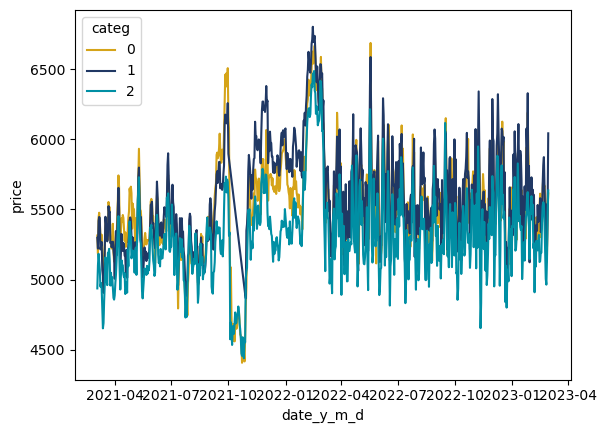

In [439]:
# pour ajouter le moyenne mobile...
sns.lineplot(
    x=df_CA_date_cat["date_y_m_d"], y=df_CA_date_cat["price"].rolling(mobile).mean(), 
    hue=df_CA_date_cat["categ"], 
#    data=df_CA_date_cat,
    palette=["#d5a419","#203864","#008fa4"],
)


In [440]:
# nombre de dates auxquelles les différentes catégories ont été vendues
print("Nr 0:",(df_CA_date_cat["categ"] == 0).sum())
print("Nr 1:",(df_CA_date_cat["categ"] == 1).sum())
print("Nr 2:",(df_CA_date_cat["categ"] == 2).sum())

Nr 0: 730
Nr 1: 704
Nr 2: 730


In [441]:
# afficher les ventes du mois d'octobre 2021
print("En effet, en octobre 2021 (2021-10-02 jusqua 2021-10-27), aucun livre de la catégorie 1 n'a été vendu, ce qui peut expliquer la baisse du CA pour cette période!")
print()
mask = (df_CA_date_cat["date_y_m_d"] > pd.Timestamp("2021-09-30").date()) & (df_CA_date_cat["date_y_m_d"] < pd.Timestamp("2021-10-29").date())
df_CA_date_cat[mask]

En effet, en octobre 2021 (2021-10-02 jusqua 2021-10-27), aucun livre de la catégorie 1 n'a été vendu, ce qui peut expliquer la baisse du CA pour cette période!



,date_y_m_d,categ,price,age
642,2021-10-01,0,6950.50,48.230769
643,2021-10-01,1,7003.79,53.011628
644,2021-10-01,2,3104.05,29.657895
645,2021-10-02,0,7141.01,47.192133
646,2021-10-02,2,2041.12,36.535714
647,2021-10-03,0,6786.57,48.120370
648,2021-10-03,2,2206.48,30.193548
649,2021-10-04,0,6533.60,48.800333
650,2021-10-04,2,2746.08,29.921053
651,2021-10-05,0,6357.91,48.927609


In [442]:
# 
print("On constate une nette baisse des ventes de livres et du chiffre d'affaires temporaire en octobre 2021, \nce dernier n'atteignant qu'environ la moitié du niveau habituel. \n\nQuelques mois plus tard, en fevrier, on constate une brève hausse du chiffre d'affaires, \navant un retour à des niveaux similaires que avant.")
print()

df_CA_date[(df_CA_date["price"] < 12000)].head()
df_CA_date[(df_CA_date["price"] < 12000)].tail()

On constate une nette baisse des ventes de livres et du chiffre d'affaires temporaire en octobre 2021, 
ce dernier n'atteignant qu'environ la moitié du niveau habituel. 

Quelques mois plus tard, en fevrier, on constate une brève hausse du chiffre d'affaires, 
avant un retour à des niveaux similaires que avant.



,date_y_m_d,price,age,categ
236,2021-10-23,8910.64,46.358804,0.156146
237,2021-10-24,9923.19,46.523885,0.140127
238,2021-10-25,8076.04,47.244367,0.110919
239,2021-10-26,9020.79,46.786284,0.114833
240,2021-10-27,9789.53,45.671848,0.169257


In [62]:
################################################################################################################
### Chiffres d'affaires par catégorie
################################################################################################################


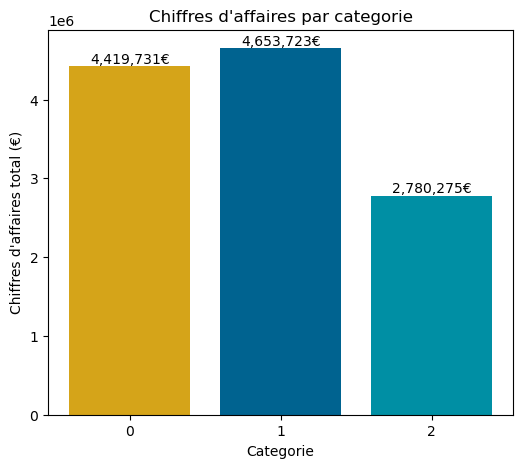

In [443]:
# calculer les chiffres d'affaires totales par catégorie
df_CA_categ = df_all[["price","age","categ","session_id","id_prod"]].groupby(by="categ").agg({"price": "sum","age": "mean","id_prod": "count"})
df_CA_categ = df_CA_categ.reset_index()
df_CA_categ = df_CA_categ.rename(columns={"id_prod": "no_livres_vendue"})

# graphique barplot
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_categ["categ"], df_CA_categ["price"],color=["#d5a419","#006390","#008fa4"])
ax.set(ylabel="Chiffres d'affaires total (€)", xlabel="Categorie", title="Chiffres d'affaires par categorie", xticks=(0,1,2))
ax.bar_label(bar_plot, fmt="{:,.0f}€")
plt.savefig("fig_CA_par_categorie.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


Comparez cela au nombre de livres vendus:



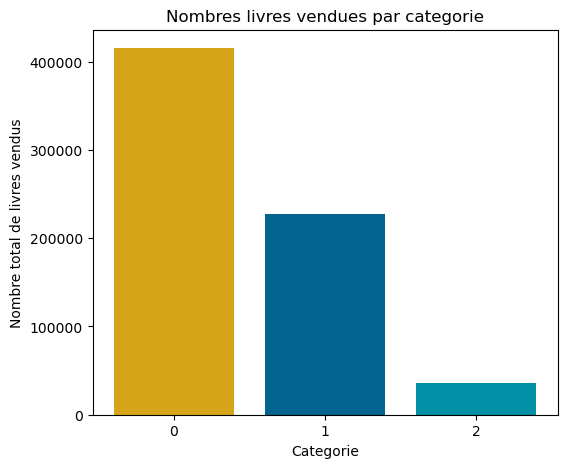

In [444]:
# Comparez cela au nombre de livres vendus...
print("Comparez cela au nombre de livres vendus:")
print()
      
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_categ["categ"], df_CA_categ["no_livres_vendue"],color=["#d5a419","#006390","#008fa4"])
ax.set(ylabel="Nombre total de livres vendus", xlabel="Categorie", title="Nombres livres vendues par categorie", xticks=(0,1,2), yticks=range(0,450000,100000))
#ax.bar_label(bar_plot, fmt="{:,.0f}")
plt.savefig("fig_nombre_vendue_par_categorie.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()


In [445]:
print(df_CA_categ["no_livres_vendue"])
print()
print(data_categ.values)

0    415459
1    227169
2     36483
Name: no_livres_vendue, dtype: int64

[2308  739  239]


Comparez cela au nombre de livres vendus par produit (ratio de nombre de livres vendus vs nombres de articles disponibles), par catégorie:



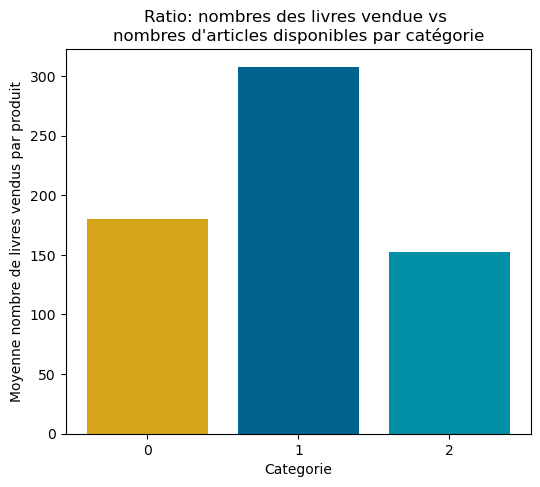

In [446]:
# Comparez cela au ratio de nombre de livres vendus vs nombres de articles disponibles par catégorie
ratio = df_CA_categ["no_livres_vendue"]/data_categ.values

print("Comparez cela au nombre de livres vendus par produit (ratio de nombre de livres vendus vs nombres de articles disponibles), par catégorie:")
print()
      
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_categ["categ"], ratio, color=["#d5a419","#006390","#008fa4"])
ax.set(ylabel="Moyenne nombre de livres vendus par produit", xlabel="Categorie", title="Ratio: nombres des livres vendue vs \nnombres d'articles disponibles par catégorie", xticks=(0,1,2) ) #, yticks=range(0,450000,100000))
#ax.bar_label(bar_plot, fmt="{:,.0f}")
plt.savefig("fig_ratio_nr_vendue_nr_articles.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

In [447]:
################################################################################################################
### Nombre de clients par mois
################################################################################################################
# Créer une nouvelle variable incluant uniquement l'année et le mois
pd.to_datetime(df_all["date_y_m_d"]).dt.to_period("M")
df_all["date_y_m"] = pd.to_datetime(df_all["date_y_m_d"]).dt.to_period("M")
df_all.head(3)

# calculer le nombre de clients par mois
df_nr_client_month = df_all[["date_y_m","client_id"]].groupby("date_y_m").nunique()
df_nr_client_month = df_nr_client_month.reset_index()

print(f"Le nombres des clients moyenne par mois: {df_nr_client_month["client_id"].mean():,.0f} personnes (l'ecarte-type: {int(round(df_nr_client_month["client_id"].std(),0))} personnes)")
print(f"Nombre minimum des clients par mois {df_nr_client_month["client_id"].min():,.0f} personnes")
print(f"Nombre maximum des clients par mois {df_nr_client_month["client_id"].max():,.0f} personnes")

Le nombres des clients moyenne par mois: 5,714 personnes (l'ecarte-type: 153 personnes)
Nombre minimum des clients par mois 5,094 personnes
Nombre maximum des clients par mois 5,875 personnes


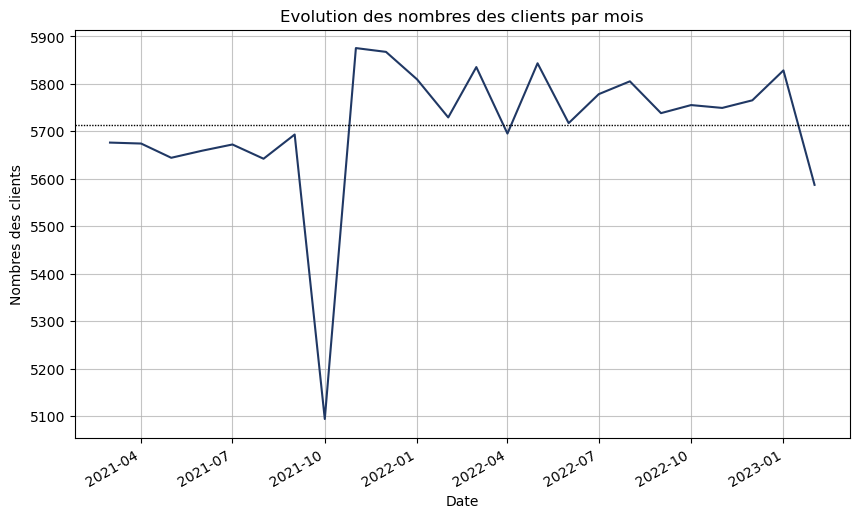

In [449]:
# création de graphique en ligne
plt.figure(figsize=(10,6))
plt.plot(
    df_nr_client_month["date_y_m"].dt.to_timestamp(),
    df_nr_client_month["client_id"], 
    #marker="o", 
    linestyle="-",
    color="#203864",
    label="Nombre de clients"
)

plt.title("Evolution des nombres des clients par mois")
plt.xlabel("Date")
plt.ylabel("Nombres des clients")
#plt.ylim(5000,6000)
#plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=1)
plt.grid(True, alpha=0.75)
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
#plt.legend(loc = 7)
plt.axhline(y=df_nr_client_month["client_id"].mean(), dashes=(1, 1), linewidth=1, color="black") # Dotted line using dashes
plt.savefig("fig_nombre_clients_moin.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

In [450]:
################################################################################################################
### Nombre de transactions
################################################################################################################
print(f"Le nombres des transactions depuis le début de la boutique en ligne: {df_all["session_id"].nunique():,.0f} transactions")

# calculer le nombre de transaction par clients
df_trans_per_client = df_all[["id_prod","session_id","client_id","price"]].groupby("client_id").agg({"session_id": "nunique","price":"mean"})
df_trans_per_client["session_id"].mean()
print()
print(f"Le nombre moyen de transactions par client: {df_trans_per_client["session_id"].mean():,.0f} transaction")
#print(df_all.loc[(df_all["client_id"] == "c_1"),"session_id"].nunique())       # contrôle
#df_trans_per_client["session_id"].head(3)                                      # contrôle

# calculer le nombres de livres par transaction
df_livre_per_trans = df_all[["id_prod","session_id","client_id","price"]].groupby("session_id").agg({"id_prod": "nunique","price":"mean"})
df_livre_per_trans = df_livre_per_trans.reset_index()

print()
print(f"Le nombre moyen de livres acheter par transactions: {df_livre_per_trans["id_prod"].mean():,.2f} livres")
#print(df_all.loc[(df_all["session_id"] == "s_1"),"id_prod"].nunique())       # contrôle
#print(df_all.loc[(df_all["session_id"] == "s_10"),"id_prod"].nunique())      # contrôle
#print(df_all.loc[(df_all["session_id"] == "s_100"),"id_prod"].nunique())     # contrôle
#df_livre_per_trans.head()                                                    # contrôle



Le nombres des transactions depuis le début de la boutique en ligne: 342,275 transactions

Le nombre moyen de transactions par client: 40 transaction

Le nombre moyen de livres acheter par transactions: 1.98 livres


In [451]:
# calculer le nombre de transactions par mois
df_nr_trans_month = df_all[["date_y_m","session_id"]].groupby("date_y_m").nunique()
df_nr_trans_month = df_nr_trans_month.reset_index()

mask_2021 = (df_nr_trans_month["date_y_m"]).dt.year == 2021
mask_2022 = (df_nr_trans_month["date_y_m"]).dt.year == 2022
mask_2023 = (df_nr_trans_month["date_y_m"]).dt.year == 2023

print(f"Le nombres des transactions moyenne par mois: {df_nr_trans_month["session_id"].mean():,.0f} transactions (l'ecarte-type: {df_nr_trans_month["session_id"].std():,.0f} transactions)")
print(f"Le nombres des transactions median par mois: {df_nr_trans_month["session_id"].median():,.0f} transactions")
print(f"Nombre minimum des transactions par mois {df_nr_trans_month["session_id"].min():,.0f} transactions")
print(f"Nombre maximum des transactions par mois {df_nr_trans_month["session_id"].max():,.0f} transactions")
print()
print(f"Le nombre moyen de transactions mensuelles en 2021: {df_nr_trans_month.loc[mask_2021,"session_id"].mean():,.0f}")
print(f"Le nombre moyen de transactions mensuelles en 2022: {df_nr_trans_month.loc[mask_2022,"session_id"].mean():,.0f}")
print(f"Le nombre moyen de transactions mensuelles en 2023: {df_nr_trans_month.loc[mask_2023,"session_id"].mean():,.0f}")


Le nombres des transactions moyenne par mois: 14,264 transactions (l'ecarte-type: 788 transactions)
Le nombres des transactions median par mois: 14,363 transactions
Nombre minimum des transactions par mois 11,551 transactions
Nombre maximum des transactions par mois 15,566 transactions

Le nombre moyen de transactions mensuelles en 2021: 13,991
Le nombre moyen de transactions mensuelles en 2022: 14,549
Le nombre moyen de transactions mensuelles en 2023: 13,916


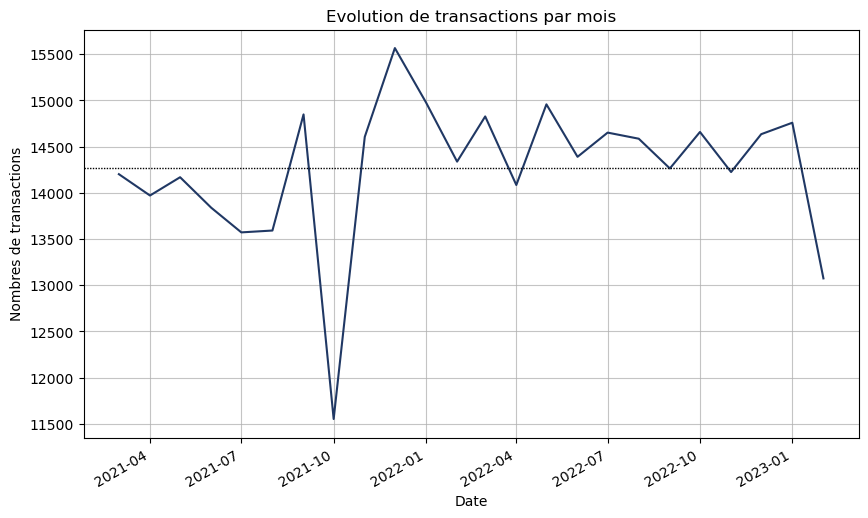

In [452]:
# création de graphique en ligne
plt.figure(figsize=(10,6))
plt.plot(
    df_nr_trans_month["date_y_m"].dt.to_timestamp(),
    df_nr_trans_month["session_id"], 
    #marker="o", 
    linestyle="-",
    color="#203864",
    label="Nombre de clients"
)
plt.title("Evolution de transactions par mois")
plt.xlabel("Date")
plt.ylabel("Nombres de transactions")
#plt.ylim(5000,6000)
#plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=1)
plt.grid(True, alpha=0.75)
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
#plt.legend(loc = 7)
plt.axhline(y=df_nr_trans_month["session_id"].mean(), dashes=(1, 1), linewidth=1, color="black") # Dotted line using dashes
plt.savefig("fig_nombre_transactions_moin.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

In [456]:
################################################################################################################
### Nombre de produits vendus
################################################################################################################
print(f"Le nombres des differents livres vendus depuis le début de la boutique en ligne: {df_all["id_prod"].nunique():,.0f} livres")
print()

# calculer le nombre de livres par clients
df_livres_per_client = df_all[["id_prod","session_id","client_id","price"]].groupby("client_id").agg({"id_prod": "nunique","price":"mean"})
df_livres_per_client = df_livres_per_client.reset_index()
print(f"Le nombre moyen de produits acheté par client: {df_livres_per_client["id_prod"].mean():,.0f} livres")
print()



Le nombres des differents livres vendus depuis le début de la boutique en ligne: 3,265 livres

Le nombre moyen de produits acheté par client: 36 livres



In [457]:
# calculer le nombre de differents produits vendue par mois
df_nr_livres_month = df_all[["date_y_m","id_prod"]].groupby("date_y_m").nunique()
df_nr_livres_month = df_nr_livres_month.reset_index()

mask_2021 = (df_nr_livres_month["date_y_m"]).dt.year == 2021
mask_2022 = (df_nr_livres_month["date_y_m"]).dt.year == 2022
mask_2023 = (df_nr_livres_month["date_y_m"]).dt.year == 2023

print(f"Le nombres moyennes des differents produits vendue par mois: {df_nr_livres_month["id_prod"].mean():,.0f} produits (l'ecarte-type: {df_nr_livres_month["id_prod"].std():,.0f} transactions)")
print(f"Nombre minimum des differents produits vendues par mois {df_nr_livres_month["id_prod"].min():,.0f} produits")
print(f"Nombre maximum des differents produits vendues par mois {df_nr_livres_month["id_prod"].max():,.0f} produits")
print()
print(f"Le nombre moyen de differents livres vendue mensuelles en 2021: {df_nr_livres_month.loc[mask_2021,"id_prod"].mean():,.0f}")
print(f"Le nombre moyen de differents livres vendue mensuelles en 2022: {df_nr_livres_month.loc[mask_2022,"id_prod"].mean():,.0f}")
print(f"Le nombre moyen de differents livres vendue mensuelles en 2023: {df_nr_livres_month.loc[mask_2023,"id_prod"].mean():,.0f}")



Le nombres moyennes des differents produits vendue par mois: 2,453 produits (l'ecarte-type: 55 transactions)
Nombre minimum des differents produits vendues par mois 2,273 produits
Nombre maximum des differents produits vendues par mois 2,560 produits

Le nombre moyen de differents livres vendue mensuelles en 2021: 2,440
Le nombre moyen de differents livres vendue mensuelles en 2022: 2,465
Le nombre moyen de differents livres vendue mensuelles en 2023: 2,448


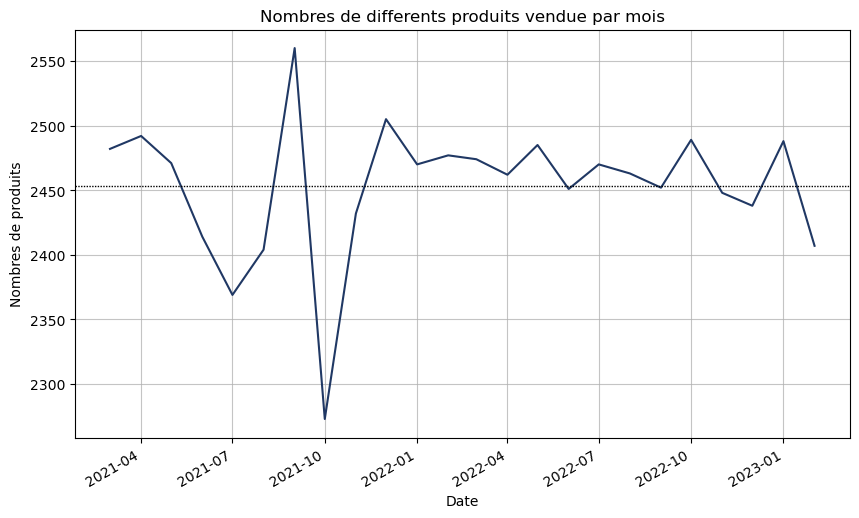

In [458]:
# création de graphique en ligne
plt.figure(figsize=(10,6))
plt.plot(
    df_nr_livres_month["date_y_m"].dt.to_timestamp(),
    df_nr_livres_month["id_prod"], 
    #marker="o", 
    linestyle="-",
    color="#203864",
    label="Nombre de clients"
)
plt.title("Nombres de differents produits vendue par mois")
plt.xlabel("Date")
plt.ylabel("Nombres de produits")
#plt.ylim(5000,6000)
#plt.yticks(range(0,22000,4000))
plt.grid(axis="y", alpha=1)
plt.grid(True, alpha=0.75)
plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
#plt.legend(loc = 7)
plt.axhline(y=df_nr_livres_month["id_prod"].mean(), dashes=(1, 1), linewidth=1, color="black") # Dotted line using dashes
plt.savefig("fig_nombre_produits_vendue_moin.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 4.2 - Les références</h3>
</div>

In [459]:
################################################################################################################
### Les tops references
################################################################################################################
# calculer le nombre de fois qu'un certain livre est vendue
df_prod_vendue = df_all[["id_prod","session_id","client_id","price","categ"]].groupby("id_prod").agg({"session_id":"count","price":"mean","categ":"min"})
# Rename the columns to be more descriptive
df_prod_vendue = df_prod_vendue.rename(columns={"session_id": "count"})
# reset l'index et trier les données
df_prod_vendue = df_prod_vendue.reset_index()
df_prod_vendue_sort = df_prod_vendue.sort_values("count", ascending=False)

df_prod_vendue_sort.head()

,id_prod,count,price,categ
2591,1_369,2252,23.99,1
2644,1_417,2189,20.99,1
2641,1_414,2180,23.83,1
2733,1_498,2128,23.37,1
2653,1_425,2096,16.99,1


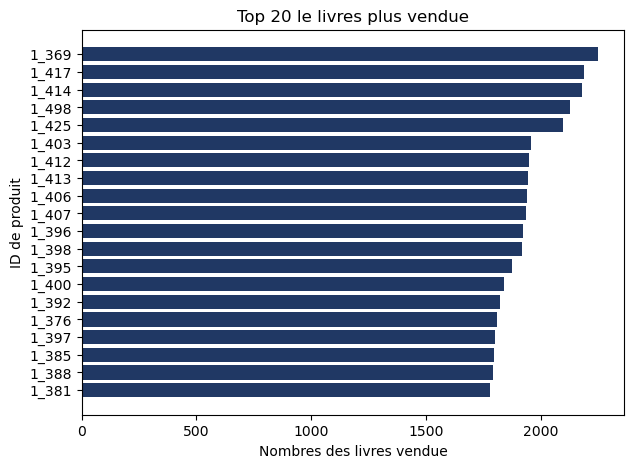

In [460]:
# graphiques de bar pour montrer les top 20 livres vendue      
df_prod_vendue_top = df_prod_vendue_sort.head(20)

fig, ax = plt.subplots(figsize=(7,5))
bar_plot = ax.barh(df_prod_vendue_top["id_prod"], df_prod_vendue_top["count"], color="#203864")
ax.set(xlabel="Nombres des livres vendue", ylabel="ID de produit", title="Top 20 le livres plus vendue")#, xticks=(0,1,2), yticks=range(0,450000,100000))
#ax.bar_label(bar_plot, fmt="{:,.0f}")
#plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
ax.invert_yaxis() 
plt.savefig("fig_top_20_vendue.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

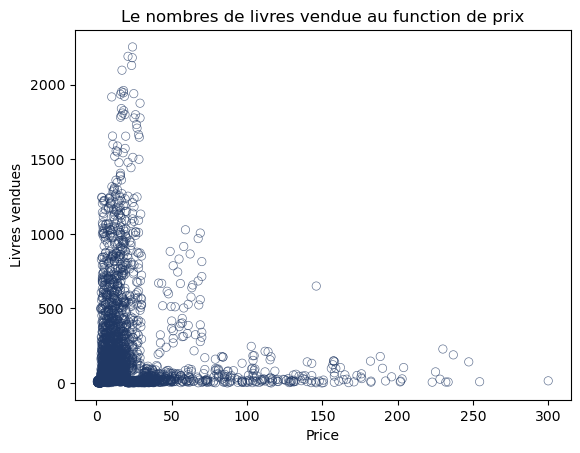


Attention! Plusieurs observations non inclus sont onsale_web = 1 (orange), 
c'est-à-dire qu'ils auraient théoriquement dû être inclus dans l'ensemble de données final.



In [461]:
# graphique scatterplot des poins pour montrant le livres les plus vendue a function du prix
sns.scatterplot(
    data=df_prod_vendue,
    x="price",
    y="count",
    color="lightgray",
    edgecolors="#203864", 
    facecolors="none",
    alpha=0.7
)
plt.xlabel("Price")
plt.ylabel("Livres vendues")
#plt.plot([0, 140], [0, 0],linewidth=0.5, color="black", linestyle="dashed")
plt.title("Le nombres de livres vendue au function de prix")
plt.show()

print()
print("Attention! Plusieurs observations non inclus sont onsale_web = 1 (orange), \nc'est-à-dire qu'ils auraient théoriquement dû être inclus dans l'ensemble de données final.")
print()

In [462]:
# calculer le nombre de fois qu'un certain livre est vendue pour les femmes et les hommes
df_all_f = df_all[df_all["sex"] == "f"]
df_all_m = df_all[df_all["sex"] == "m"]

df_prod_vendue_f = df_all_f[["id_prod","session_id","client_id","price"]].groupby("id_prod").agg({"session_id":"count","price":"mean"})
df_prod_vendue_m = df_all_m[["id_prod","session_id","client_id","price"]].groupby("id_prod").agg({"session_id":"count","price":"mean"})
# Rename the columns to be more descriptive
df_prod_vendue_f = df_prod_vendue_f.rename(columns={"session_id": "count"})
df_prod_vendue_m = df_prod_vendue_m.rename(columns={"session_id": "count"})
# reset l'index et trier les données
df_prod_vendue_f = df_prod_vendue_f.reset_index()
df_prod_vendue_m = df_prod_vendue_m.reset_index()
df_prod_vendue_sort_f = df_prod_vendue_f.sort_values("count", ascending=False)
df_prod_vendue_sort_m = df_prod_vendue_m.sort_values("count", ascending=False)

print(df_prod_vendue_sort_f.head())
print(df_prod_vendue_sort_m.head())

     id_prod  count  price
2520   1_369   1128  23.99
2571   1_417   1123  20.99
2568   1_414   1092  23.83
2579   1_425   1079  16.99
2658   1_498   1077  23.37
     id_prod  count  price
2516   1_369   1124  23.99
2562   1_414   1088  23.83
2565   1_417   1066  20.99
2654   1_498   1051  23.37
2574   1_425   1017  16.99


Test - les 20 livres les plus populaires sont les mêmes pour les femmes et les hommes: False



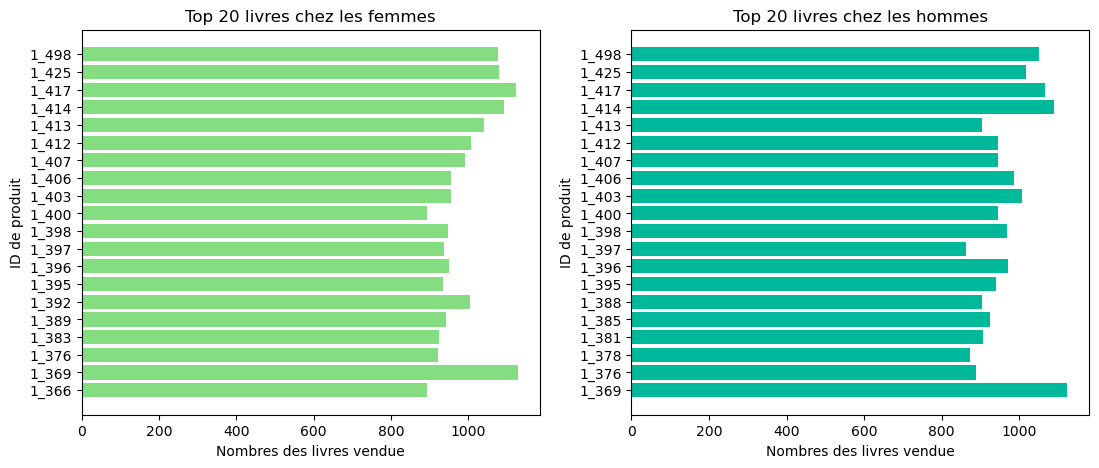

In [463]:
# graphiques de bar pour montrer les top 20 livres vendue      
df_prod_vendue_top_f = df_prod_vendue_sort_f.head(20).sort_values("id_prod")
df_prod_vendue_top_m = df_prod_vendue_sort_m.head(20).sort_values("id_prod")

fig, ax = plt.subplots(1,2,figsize=(13,5)) 
# les top 20 livres pour les fammes
bar_plot = ax[0].barh(df_prod_vendue_top_f["id_prod"], df_prod_vendue_top_f["count"], color="#84de81")
ax[0].set(ylabel="ID de produit", xlabel="Nombres des livres vendue", title="Top 20 livres chez les femmes")#, xticks=(0,1,2), yticks=range(0,450000,100000))

# les top 20 livres pour les hommes
bar_plot = ax[1].barh(df_prod_vendue_top_m["id_prod"], df_prod_vendue_top_m["count"], color="#00b99a")
ax[1].set(ylabel="ID de produit", xlabel="Nombres des livres vendue", title="Top 20 livres chez les hommes")#, xticks=(0,1,2), yticks=range(0,450000,100000))

print("Test - les 20 livres les plus populaires sont les mêmes pour les femmes et les hommes:",set(df_prod_vendue_top_m["id_prod"]) == set(df_prod_vendue_top_f["id_prod"]) )
print()
plt.savefig("fig_top_20_vendue_f_m.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

In [464]:
################################################################################################################
### Les flops references
################################################################################################################
# les top 20 flops - les references moin vendue 
df_prod_vendue_flop = df_prod_vendue_sort.tail(20)


montre aussi les produits non vendue...



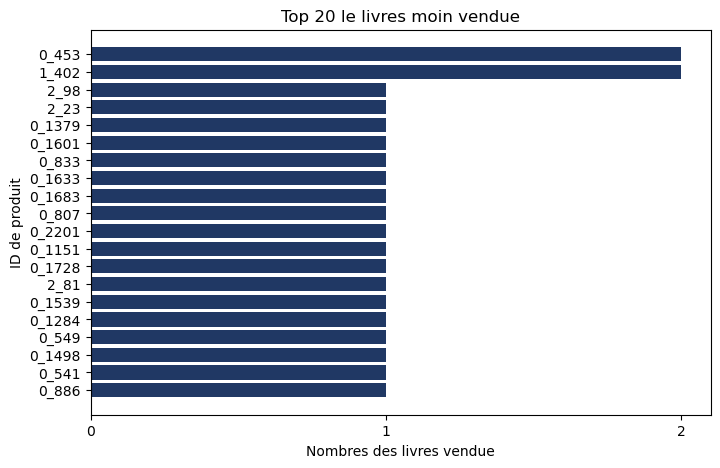

In [465]:
# graphiques de bar pour montrer les top 20 flops livres vendue      
df_prod_vendue_flop = df_prod_vendue_sort.tail(20)

fig, ax = plt.subplots(figsize=(8,5))
bar_plot = ax.barh(df_prod_vendue_flop["id_prod"], df_prod_vendue_flop["count"], color="#203864")
ax.set(ylabel="ID de produit", xlabel="Nombres des livres vendue", title="Top 20 le livres moin vendue", xticks=(0,1,2)) #, yticks=range(0,450000,100000))
#ax.bar_label(bar_plot, fmt="{:,.0f}")
#plt.gcf().autofmt_xdate()  # Rotation automatique des dates pour une meilleure lisibilité
ax.invert_yaxis() 

print("montre aussi les produits non vendue...")
print()
plt.savefig("fig_flop_20_vendue.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

In [466]:
# les flops total - des livres pas vendue les 2 derniere années...
produits_non_vendue["id_prod"]

6073      0_1014
6511      0_1016
8723      0_1025
21687     0_1062
40971     0_1119
94245     0_1318
297077    0_1620
299185    0_1624
311123    0_1645
323013    0_1780
325137    0_1800
387872    0_2308
389947     0_299
390442     0_310
390910     0_322
397291     0_510
415696       1_0
511418     1_394
677796      2_72
678299      2_86
678300      2_87
Name: id_prod, dtype: object

In [467]:
################################################################################################################
### Répartition par catégorie
################################################################################################################
df_prod_vendue_sort.head()

,id_prod,count,price,categ
2591,1_369,2252,23.99,1
2644,1_417,2189,20.99,1
2641,1_414,2180,23.83,1
2733,1_498,2128,23.37,1
2653,1_425,2096,16.99,1


In [468]:
# les top par catégorie
mask0 = df_prod_vendue["categ"] == 0
df_prod_vendue_categ_0 = df_prod_vendue[mask0]
df_prod_vendue_categ_0_sort = df_prod_vendue_categ_0.sort_values("count", ascending=False)
df_prod_vendue_categ_0_sort.head(10)

mask1 = df_prod_vendue["categ"] == 1
df_prod_vendue_categ_1 = df_prod_vendue[mask1]
df_prod_vendue_categ_1_sort = df_prod_vendue_categ_1.sort_values("count", ascending=False)
df_prod_vendue_categ_1_sort.head(10)

mask2 = df_prod_vendue["categ"] == 2
df_prod_vendue_categ_2 = df_prod_vendue[mask2]
df_prod_vendue_categ_2_sort = df_prod_vendue_categ_2.sort_values("count", ascending=False)
df_prod_vendue_categ_2_sort.head(10)


,id_prod,count,price,categ
3034,2_102,1027,59.14,2
3070,2_135,1005,68.99,2
3045,2_112,968,67.57,2
3201,2_39,915,57.99,2
3199,2_37,882,48.99,2
3043,2_110,865,62.25,2
3151,2_208,831,54.87,2
3152,2_209,814,69.99,2
3150,2_207,786,50.99,2
3041,2_109,744,53.99,2


Test - les 20 livres les plus populaires sont les mêmes pour les femmes et les hommes: True



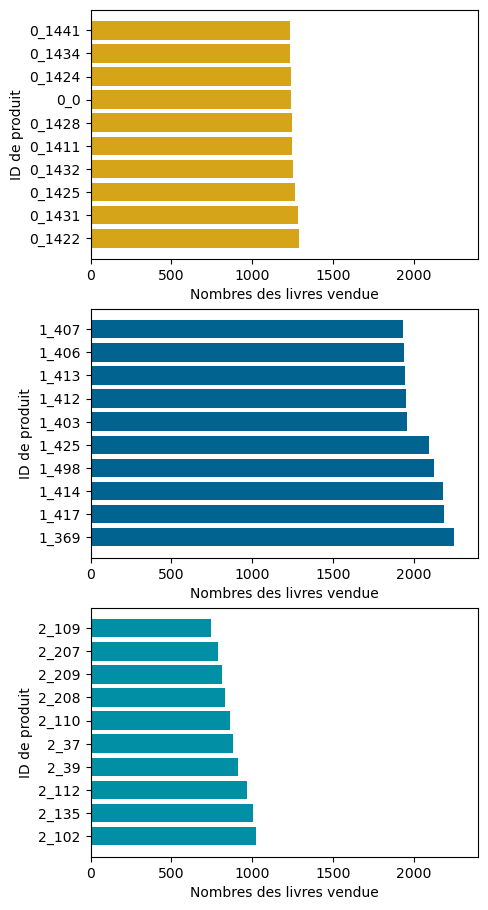

In [472]:
# graphiques de bar pour montrer les top 20 livres vendue      
df_prod_vendue_categ_0_sort = df_prod_vendue_categ_0_sort.head(10)
df_prod_vendue_categ_1_sort = df_prod_vendue_categ_1_sort.head(10)
df_prod_vendue_categ_2_sort = df_prod_vendue_categ_2_sort.head(10)

fig, ax = plt.subplots(3,1,figsize=(5,11))
# les top 20 livres pour categorie 0
bar_plot = ax[0].barh(df_prod_vendue_categ_0_sort["id_prod"], df_prod_vendue_categ_0_sort["count"], color=["#d5a419"])
ax[0].set(ylabel="ID de produit", xlabel="Nombres des livres vendue", xlim=(0,2400))#, xticks=(0,1,2), yticks=range(0,450000,100000))

# les top 20 livres pour categorie 1
bar_plot = ax[1].barh(df_prod_vendue_categ_1_sort["id_prod"], df_prod_vendue_categ_1_sort["count"], color="#006390")
ax[1].set(ylabel="ID de produit", xlabel="Nombres des livres vendue", xlim=(0,2400))#, xticks=(0,1,2), yticks=range(0,450000,100000))

# les top 20 livres pour categorie 2
bar_plot = ax[2].barh(df_prod_vendue_categ_2_sort["id_prod"], df_prod_vendue_categ_2_sort["count"], color="#008fa4")
ax[2].set(ylabel="ID de produit", xlabel="Nombres des livres vendue", xlim=(0,2400))#, xticks=(0,1,2), yticks=range(0,450000,100000))

print("Test - les 20 livres les plus populaires sont les mêmes pour les femmes et les hommes:",set(df_prod_vendue_top_m) == set(df_prod_vendue_top_f) )
print()
plt.savefig("fig_top_10_vendue_par_categ.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

In [473]:
# prix moyenne de ce livres
print("Prix moyenne de top 10 catégorie 0:",df_prod_vendue_categ_0_sort["price"].mean())
print("Prix moyenne de top 10 catégorie 0:",df_prod_vendue_categ_1_sort["price"].mean())
print("Prix moyenne de top 10 catégorie 0:",df_prod_vendue_categ_2_sort["price"].mean())

Prix moyenne de top 10 catégorie 0: 10.302
Prix moyenne de top 10 catégorie 0: 20.26
Prix moyenne de top 10 catégorie 0: 59.477


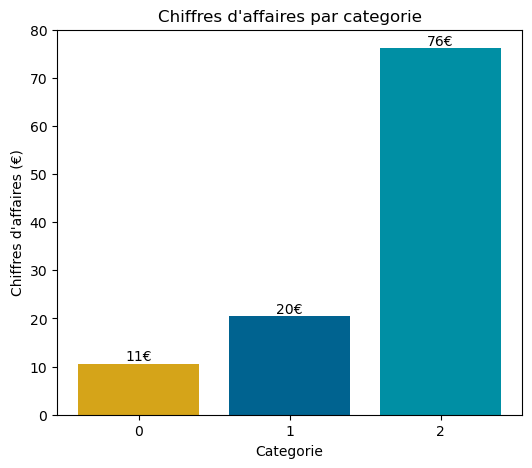

In [474]:
# calculer les chiffres d'affaires (moyenne!?... change a total...?) totales par catégorie     # Trial - Can be deleted! 
df_prix_categ = df_all[["price","categ"]].groupby(by="categ").agg({"price": ["mean", "std"]})

# graphique barplot
fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_prix_categ["price"].index,df_prix_categ["price"]["mean"],color=["#d5a419","#006390","#008fa4"])
ax.set(ylabel="Chiffres d'affaires (€)", xlabel="Categorie", title="Chiffres d'affaires par categorie", xticks=(0,1,2))
ax.bar_label(bar_plot, fmt="{:,.0f}€")
#plt.errorbar(df_prix_categ["price"].index,df_prix_categ["price"]["mean"], 
#             yerr=[(df_prix_categ["price"]["std"]),(df_prix_categ["price"]["std"])], 
#             fmt='o',color="b")
plt.show()


C:\Users\matil\AppData\Local\Temp\ipykernel_26128\1717620684.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




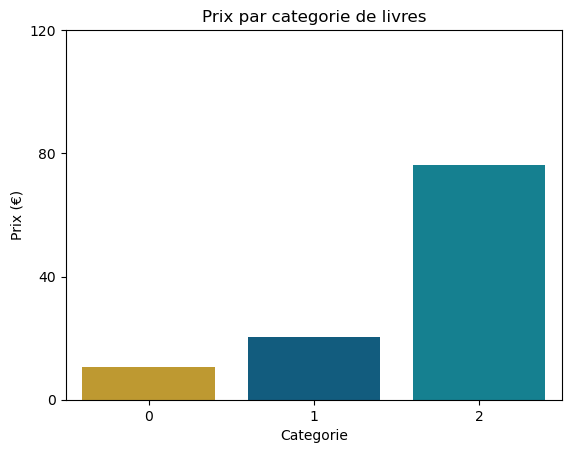

In [475]:
# prix par categorie de livres
ax = sns.barplot(x = df_prix_categ["price"].index, y = df_prix_categ["price"]["mean"], palette=["#d5a419","#006390","#008fa4"])
ax.set(xlabel="Categorie", ylabel="Prix (€)", title="Prix par categorie de livres", yticks=range(0,125,40))
plt.show()

C:\Users\matil\AppData\Local\Temp\ipykernel_26128\2683656207.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




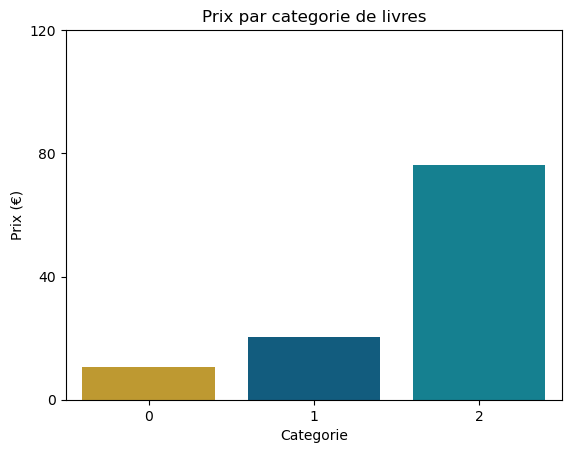

In [476]:
# calculer le prix moyenne par catégorie
df_prix_categ = df_all[["price","categ"]].groupby(by="categ").agg({"price": ["mean", "std"]})

ax = sns.barplot(x = df_prix_categ["price"].index, y = df_prix_categ["price"]["mean"], palette=["#d5a419","#006390","#008fa4"])
ax.set(xlabel="Categorie", ylabel="Prix (€)", title="Prix par categorie de livres", yticks=range(0,125,40))
#plt.errorbar(df_prix_categ["price"].index,df_prix_categ["price"]["mean"], 
#             yerr=[(df_prix_categ["price"]["std"]),(df_prix_categ["price"]["std"])], 
#             fmt='o',color="b")
plt.show()

<div style="border: 1px solid RGB(255,255,255);" >
<h3 style="margin: auto; padding: 20px; color: RGB(255,255,255); ">Etape 4.3 - Les profils de clients </h3>
</div>

In [479]:
################################################################################################################
### Répartition du chiffres d'affaires pour les clients B to B   (Business to Business)
################################################################################################################
# calculer le CA par client
#df_CA_client = df_all[["client_id","price"]].groupby("client_id").sum()
df_CA_client = df_all[["client_id","price","session_id","id_prod","sex","age","categ","date_y_m_d"]].groupby("client_id").agg({"price":"sum","session_id":"nunique","id_prod":"count","sex":"min","age":"min","categ":"mean"})
df_CA_client = df_CA_client.sort_values("price", ascending=False)

df_CA_client = df_CA_client.rename(columns={"price": "CA", "session_id":"nr_trans","id_prod":"nr_livre","categ":"categ_moy"})
df_CA_client = df_CA_client.reset_index()

df_CA_client.head()

,client_id,CA,nr_trans,nr_livre,sex,age,categ_moy
0,c_1609,324033.35,10997,25488,m,46,0.209196
1,c_4958,289760.34,3851,5195,m,27,1.635034
2,c_6714,153598.92,2620,9181,f,58,0.454635
3,c_3454,113637.93,5570,6770,m,57,0.604284
4,c_3263,5276.87,143,403,f,41,0.220844


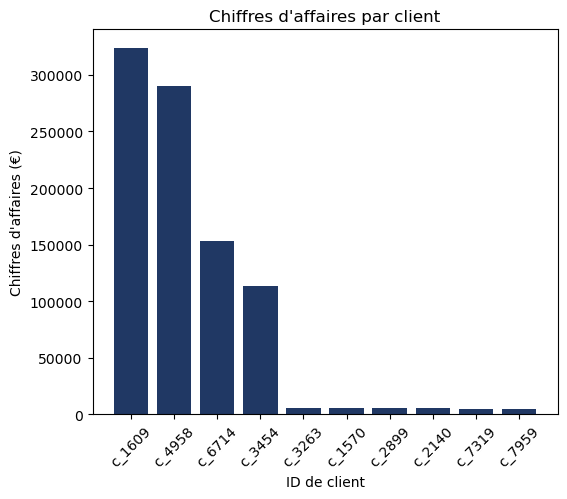

In [480]:
# graphique sur les top 10 clients en chiffres d'affaires
df_CA_client_top10 = df_CA_client.head(10)

fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_client_top10["client_id"], df_CA_client_top10["CA"], color=["#203864"]) # "#b0c4de"
ax.set(xlabel="ID de client", ylabel="Chiffres d'affaires (€)", title="Chiffres d'affaires par client" )#, yticks=range(0,350000,100000))
ax.tick_params(axis="x", labelrotation=45)

print()
plt.savefig("fig_top_10_CA.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

In [481]:
# Analyse complémentaire sur les 4 principaux clients B to B
df_CA_client_top4 = df_CA_client.head(4)
print(f"CA moyenne client B to B: {df_CA_client_top4["CA"].mean():,.0f}")
print(f"CA std client B to B: {df_CA_client_top4["CA"].std():,.0f}")
print(f"CA medien client B to B: {df_CA_client_top4["CA"].median():,.0f}")
print()

print(f"No transactions moyenne client B to B: {df_CA_client_top4["nr_trans"].mean():,.0f}")
print(f"No transactions std client B to B: {df_CA_client_top4["nr_trans"].std():,.0f}")
print(f"No transactions medien client B to B: {df_CA_client_top4["nr_trans"].median():,.0f}")
print()

print(f"No livres moyenne client B to B: {df_CA_client_top4["nr_livre"].mean():,.0f}")
print(f"No livres std client B to B: {df_CA_client_top4["nr_livre"].std():,.0f}")
print(f"No livres medien client B to B: {df_CA_client_top4["nr_livre"].median():,.0f}")
print()

df_CA_client_top4.head()

CA moyenne client B to B: 220,258
CA std client B to B: 102,325
CA medien client B to B: 221,680

No transactions moyenne client B to B: 5,760
No transactions std client B to B: 3,695
No transactions medien client B to B: 4,710

No livres moyenne client B to B: 11,658
No livres std client B to B: 9,364
No livres medien client B to B: 7,976



,client_id,CA,nr_trans,nr_livre,sex,age,categ_moy
0,c_1609,324033.35,10997,25488,m,46,0.209196
1,c_4958,289760.34,3851,5195,m,27,1.635034
2,c_6714,153598.92,2620,9181,f,58,0.454635
3,c_3454,113637.93,5570,6770,m,57,0.604284


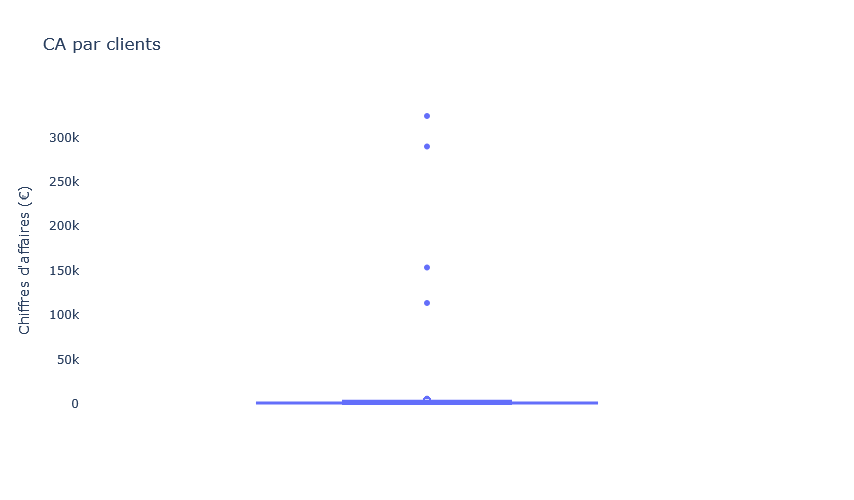

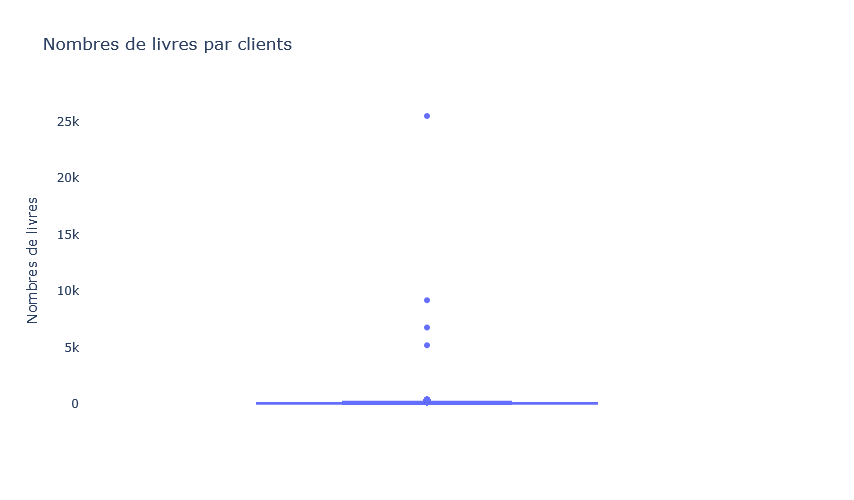

In [482]:
# visualise le distribution de chiffres d'affaires et les nombres de livres achetes
# boxplot pour le CA
fig = px.box(
    df_CA_client,
    y="CA",
    points="suspectedoutliers",
    title="CA par clients",
    width=400, height=500,
)
fig.update_layout(
    yaxis_title="Chiffres d'affaires (€)",
    plot_bgcolor="white"
)
fig.show()
print()
# boxplot pour nombre de livres achéte
fig = px.box(
    df_CA_client,
    y="nr_livre",
    points="suspectedoutliers",
    title="Nombres de livres par clients",
    width=400, height=500
)
fig.update_layout(
    yaxis_title="Nombres de livres",
    plot_bgcolor="white"
)
fig.show()
print()

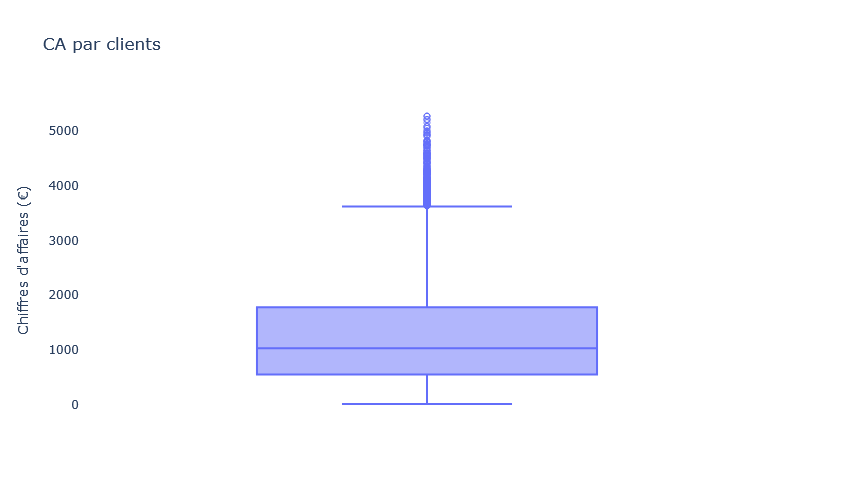

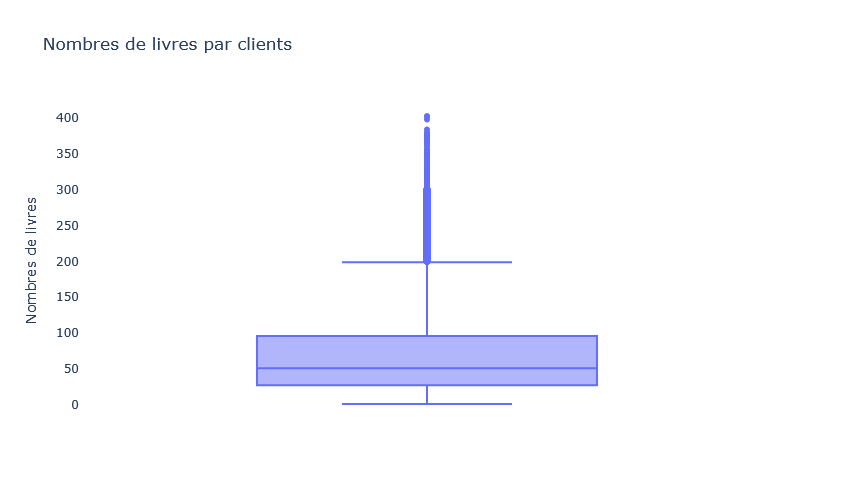

In [483]:
# visualise le distribution de chiffres d'affaires et les nombres de livres achetes - sans Top 4
mask = df_CA_client["CA"] < 50000
df_CA_client_red = df_CA_client[mask] 
# boxplot pour le CA
fig = px.box(
    df_CA_client_red,
    y="CA",
    points="suspectedoutliers",
    title="CA par clients",
    width=400, height=500
)
fig.update_layout(
    yaxis_title="Chiffres d'affaires (€)",
    plot_bgcolor="white"
)
fig.show()
print()
# boxplot pour nombre de livres achéte
fig = px.box(
    df_CA_client_red,
    y="nr_livre",
    points="suspectedoutliers",
    title="Nombres de livres par clients",
    width=400, height=500
)
fig.update_layout(
    yaxis_title="Nombres de livres",
    plot_bgcolor="white"
)
fig.show()
print()

In [484]:
# Analyse comparative sur les 4 principaux clients B to B et les autres clients
mask = df_CA_client["CA"] < 50000
df_CA_client_red = df_CA_client[mask] 

print(f"CA total clients B to B: {df_CA_client_top4["CA"].sum():,.0f}")
print(f"CA total clients sans B to B: {df_CA_client_red["CA"].sum():,.0f}")
print(f"Proportion de CA par client B to B: {((df_CA_client_top4["CA"].sum()/df_all["price"].sum())*100):,.2f}%")
print()

print(f"No transactions total de clients B to B: {df_CA_client_top4["nr_trans"].sum():,.0f}")
print(f"No transactions total de clients sans B to B: {df_CA_client_red["nr_trans"].sum():,.0f}")
print(f"Proportion des transactions total de client B to B: {((df_CA_client_top4["nr_trans"].sum()/df_all["session_id"].nunique())*100):,.2f}%")
print()

print(f"No livres total achete par clients B to B: {df_CA_client_top4["nr_livre"].sum():,.0f}")
print(f"No livres total achete par clients sans B to B: {df_CA_client_red["nr_livre"].sum():,.0f}")
print(f"Proportion No livres achete par client B to B: {((df_CA_client_top4["nr_livre"].sum()/df_all["id_prod"].count())*100):,.2f}%")
print()

print(f"proportion de clients B to B: {((df_CA_client_top4["client_id"].nunique()/df_all["client_id"].nunique())*100):,.2f}%")


CA total clients B to B: 881,031
CA total clients sans B to B: 10,972,698
Proportion de CA par client B to B: 7.43%

No transactions total de clients B to B: 23,038
No transactions total de clients sans B to B: 319,237
Proportion des transactions total de client B to B: 6.73%

No livres total achete par clients B to B: 46,634
No livres total achete par clients sans B to B: 632,477
Proportion No livres achete par client B to B: 6.87%

proportion de clients B to B: 0.05%


In [485]:
# top 10 client sans B to B
print("Moyenne age des top 10 clients:",df_CA_client_red_top10["age"].mean())
print("Ecart-type age des top 10 clients:",df_CA_client_red_top10["age"].std())
print("Moyenne nombres de livres achete des top 10 clients:",df_CA_client_red_top10["nr_livre"].mean())
print()
df_CA_client_red_top10

Moyenne age des top 10 clients: 44.3
Ecart-type age des top 10 clients: 8.206366092518932
Moyenne nombres de livres achete des top 10 clients: 324.6



,client_id,CA,nr_trans,nr_livre,sex,age,categ_moy
4,c_3263,5276.87,143,403,f,41,0.220844
5,c_1570,5271.62,158,369,f,47,0.298103
6,c_2899,5214.05,69,105,f,32,1.552381
7,c_2140,5208.82,147,402,f,49,0.231343
8,c_7319,5155.77,145,371,f,52,0.264151
9,c_7959,5085.45,146,369,f,52,0.208672
10,c_8026,5082.58,145,376,m,48,0.204787
11,c_7421,5050.20,155,379,m,48,0.226913
12,c_5263,5006.85,68,98,m,28,1.408163
13,c_1422,4993.55,149,374,f,46,0.251337


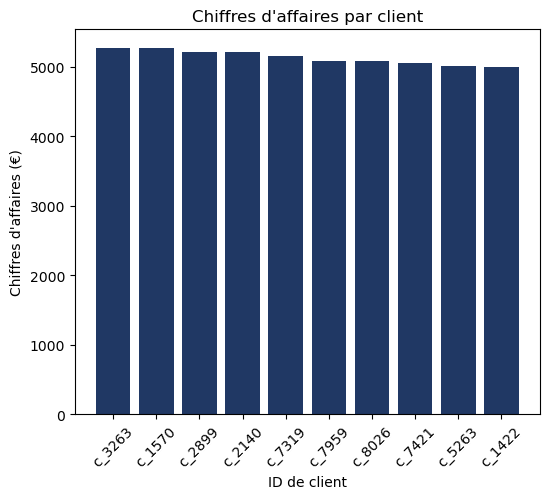

In [486]:
# graphique sur les top 10 clients en Chiffres d'affaires sans B to B
df_CA_client_red_top10 = df_CA_client_red.head(10)

fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_client_red_top10["client_id"], df_CA_client_red_top10["CA"], color="#203864")
ax.set(xlabel="ID de client", ylabel="Chiffres d'affaires (€)", title="Chiffres d'affaires par client" )#, yticks=range(0,350000,100000))
ax.tick_params(axis="x", labelrotation=45)

print()
plt.savefig("fig_top_10_CA_sans_BtoB.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

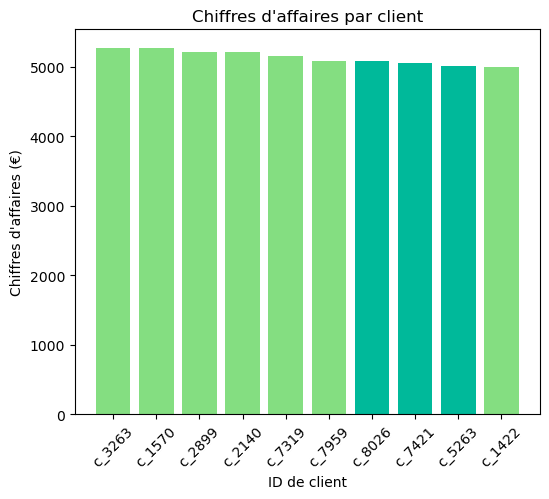

In [487]:
# graphique sur les top 10 clients en Chiffres d'affaires sans B to B - coleur par genre
df_CA_client_red_top10 = df_CA_client_red.head(10)

fig, ax = plt.subplots(figsize=(6,5))
bar_plot = ax.bar(df_CA_client_red_top10["client_id"], df_CA_client_red_top10["CA"], color=["#84de81","#84de81","#84de81","#84de81","#84de81","#84de81","#00b99a","#00b99a","#00b99a","#84de81"])
ax.set(xlabel="ID de client", ylabel="Chiffres d'affaires (€)", title="Chiffres d'affaires par client" )#, yticks=range(0,350000,100000))
ax.tick_params(axis="x", labelrotation=45)

print()
plt.savefig("fig_top_10_CA_sans_BtoB_par_genre.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
plt.show()

In [488]:
# enregistrez l'identifiant client pour l'entreprise - pour des analyses ultérieure
client_id_BtoB = df_CA_client_top10.head(4)["client_id"]
mask = df_CA_client["CA"] <= 94
client_id_BtoB_big = df_CA_client[~mask]["client_id"]
client_id_BtoB

0    c_1609
1    c_4958
2    c_6714
3    c_3454
Name: client_id, dtype: object

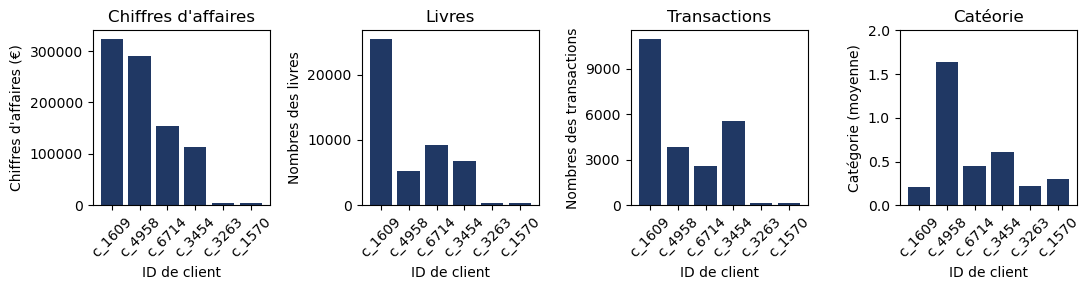

In [343]:
# Regardez le nombre de livres achetés, le nombre de transactions et la catégorie achetée par les clients B to B
df_CA_client_top10 = df_CA_client.head(6)

fig, ax = plt.subplots(1,4,figsize=(11,3))
# CA
bar_plot = ax[0].bar(df_CA_client_top10["client_id"], df_CA_client_top10["CA"], color="#203864") # ["#b0c4de","#b0c4de","#b0c4de","#203864","#b0c4de","#b0c4de"]
ax[0].set(xlabel="ID de client", ylabel="Chiffres d'affaires (€)", title="Chiffres d'affaires", yticks=range(0,400000,100000))
ax[0].tick_params(axis="x", labelrotation=45)

# Nombres des livres
bar_plot = ax[1].bar(df_CA_client_top10["client_id"], df_CA_client_top10["nr_livre"], color="#203864")
ax[1].set(xlabel="ID de client", ylabel="Nombres des livres", title="Livres", yticks=range(0,26000,10000))
ax[1].tick_params(axis="x", labelrotation=45)

# Nombres des transactions
bar_plot = ax[2].bar(df_CA_client_top10["client_id"], df_CA_client_top10["nr_trans"], color="#203864")
ax[2].set(xlabel="ID de client", ylabel="Nombres des transactions", title="Transactions", yticks=range(0,11000,3000))
ax[2].tick_params(axis="x", labelrotation=45)

# Categorie achete - valeur moyenne 
bar_plot = ax[3].bar(df_CA_client_top10["client_id"], df_CA_client_top10["categ_moy"], color="#203864")
ax[3].set(xlabel="ID de client", ylabel="Catégorie (moyenne)", title="Catéorie", yticks=(0,0.5,1,1.5,2))
ax[3].tick_params(axis="x", labelrotation=45)

plt.savefig("fig_top_10_CA_livres_trans_prix_moy.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.
fig.tight_layout()
plt.show()

In [116]:
################################################################################################################
### Courbe de Lorenz
################################################################################################################

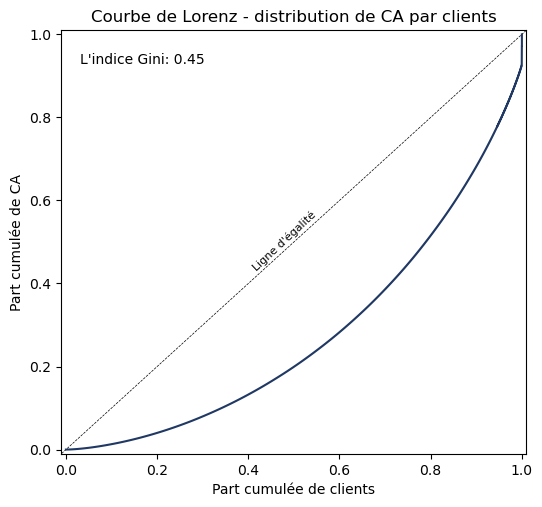

In [490]:
# La courbe de Lorenz => Clients!  
dep = df_CA_client["CA"]
n = len(dep)
lorenz = np.cumsum(np.sort(dep)) / dep.sum()
lorenz = np.append([0],lorenz) # La courbe de Lorenz commence à 0

plt.subplots(figsize=(6,5.5))
xaxis = np.linspace(0-1/n,1+1/n,n+1) #Il y a un segment de taille n pour chaque individu, plus 1 segment supplémentaire d'ordonnée 0. Le premier segment commence à 0-1/n, et le dernier termine à 1+1/n.
plt.plot([-0.5, 1.5], [-0.5, 1.5],linewidth=0.5, color="black", linestyle="dashed")
plt.plot(xaxis,lorenz,drawstyle="steps-post", color="#203864")
plt.title("Courbe de Lorenz - distribution de CA par clients")
plt.xlabel("Part cumulée de clients")
plt.ylabel("Part cumulée de CA")
plt.xlim(-0.01,1.01)
plt.ylim(-0.01,1.01)

# L'indice Gini
AUC = (lorenz.sum() -lorenz[-1]/2 -lorenz[0]/2)/n # Surface sous la courbe de Lorenz. Le premier segment (lorenz[0]) est à moitié en dessous de 0, on le coupe donc en 2, on fait de même pour le dernier segment lorenz[-1] qui est à moitié au dessus de 1.
S = 0.5 - AUC # surface entre la première bissectrice et le courbe de Lorenz
gini = 2*S

plt.text(0.03, 0.93, f"L'indice Gini: {gini:,.2f}", fontsize=10)
plt.text(0.48, 0.43, "Ligne d'égalité", fontsize=8, ha="center", rotation=43)
plt.savefig("fig_Courbe_Lorenz_CA.jpeg",bbox_inches="tight") # S'assurer que toute la zone de tracé est incluse, légende comprise.

plt.show()

In [492]:
################################################################################################################
# Pour une analyse plus approfondie du comportement des clients, nous enregistrons l'ensemble de données et 
# effectuons l'analyse suivante dans le notebook Haraldsson Matilda 1b_022026

print("Les clients exclus: \n",client_id_BtoB)
mask = df_all["client_id"].isin(client_id_BtoB)
df_all_sans_BtoB = df_all[~mask]
print()

#Mettre le dataset df_all_sans_BtoB sur un fichier csv
#Cette étape peut être utile pour partager le résultat du dataset obtenu avec les équipes.  
df_all_sans_BtoB.to_csv("./df_all_sans_BtoB.csv")

df_all_sans_BtoB.head(3)



Les clients exclus: 
 0    c_1609
1    c_4958
2    c_6714
3    c_3454
Name: client_id, dtype: object



,id_prod,date,session_id,client_id,sex,birth,age,price,categ,date_y_m_d,date_y_m,age_decade
480353,0_1259,2021-03-01 00:01:07.843138,s_1,c_329,f,1967,59,11.99,0,2021-03-01,2021-03,50
428221,0_1390,2021-03-01 00:02:26.047414,s_2,c_664,m,1960,66,19.37,0,2021-03-01,2021-03,60
462423,0_1352,2021-03-01 00:02:38.311413,s_3,c_580,m,1988,38,4.50,0,2021-03-01,2021-03,30
